In [1]:
# Import libraries and packages

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Mount Google drive for access to files

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## **Data loading, cleaning and extraction from existing datasets**

### Creating Best Picture dataset

In [ ]:
# load Varadi's Best Picture csv and convert to df

bp_var_id = '1cqMHCT-ErFzPXSy6uyinBFPWCMwdLYcI'
bp_var_url = f'https://drive.google.com/uc?id={bp_var_id}'

bp_var = pd.read_csv(bp_var_url)

In [ ]:
# see dataframe

bp_var

,Category,Film,Nominee,Winner,Year,Rating_IMDB,Release_date,Rating_rtaudience,Rating_rtcritic,Oscarstat_totalnoms,...,Nonom_Criticschoice,Nom_Criticschoice,Nowin_SAG_bestcast,Win_SAG_bestcast,Nonom_SAG_bestcast,Nom_SAG_bestcast,Nowin_PGA,Win_PGA,Nonom_PGA,Nom_PGA
0,Picture,The Apartment,The Apartment,1,1961,8.3,1960-09-16,94,93,10,...,0,0,0,0,0,0,0,0,0,0
1,Picture,The Alamo,The Alamo,0,1961,6.9,1960-10-24,64,50,6,...,0,0,0,0,0,0,0,0,0,0
2,Picture,Elmer Gantry,Elmer Gantry,0,1961,7.9,1960-07,86,96,5,...,0,0,0,0,0,0,0,0,0,0
3,Picture,Sons and Lovers,Sons and Lovers,0,1961,7.3,1960-07-22,54,75,7,...,0,0,0,0,0,0,0,0,0,0
4,Picture,The Sundowners,The Sundowners,0,1961,7.2,1961-02-28,62,78,5,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
385,Picture,Emilia Pérez,Emilia Pérez,0,2025,5.9,2024-11-13,19,74,13,...,0,1,1,0,0,1,1,0,0,1
386,Picture,I'm Still Here,I'm Still Here,0,2025,8.8,2025-02-07,95,99,3,...,1,0,1,0,1,0,1,0,1,0
387,Picture,Nickel Boys,Nickel Boys,0,2025,7.6,2025-01-03,76,90,2,...,0,1,1,0,1,0,1,0,1,0
388,Picture,The Substance,The Substance,0,2025,7.3,2024-09-20,75,89,5,...,0,1,1,0,1,0,1,0,0,1


In [ ]:
# examine data types

bp_var.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 390 entries, 0 to 389
Data columns (total 60 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Category                    390 non-null    object 
 1   Film                        390 non-null    object 
 2   Nominee                     390 non-null    object 
 3   Winner                      390 non-null    int64  
 4   Year                        390 non-null    int64  
 5   Rating_IMDB                 390 non-null    float64
 6   Release_date                390 non-null    object 
 7   Rating_rtaudience           390 non-null    int64  
 8   Rating_rtcritic             390 non-null    int64  
 9   Oscarstat_totalnoms         390 non-null    int64  
 10  Release_Q1                  390 non-null    int64  
 11  Release_Q2                  390 non-null    int64  
 12  Release_Q3                  390 non-null    int64  
 13  Release_Q4                  390 non

In [ ]:
# checking for duplicates

duplicates = bp_var[bp_var.duplicated()]

duplicates

,Category,Film,Nominee,Winner,Year,Rating_IMDB,Release_date,Rating_rtaudience,Rating_rtcritic,Oscarstat_totalnoms,...,Nonom_Criticschoice,Nom_Criticschoice,Nowin_SAG_bestcast,Win_SAG_bestcast,Nonom_SAG_bestcast,Nom_SAG_bestcast,Nowin_PGA,Win_PGA,Nonom_PGA,Nom_PGA


In [ ]:
# create new Best Picture dataframe with the relevant columns

pic_df = bp_var[['Film', 'Year', 'Winner', 'Oscarstat_totalnoms', 'Nom_Oscar_bestdirector', 'Rating_IMDB', 'Rating_rtaudience', 'Rating_rtcritic',
                  'Release_Q1', 'Release_Q2', 'Release_Q3', 'Release_Q4',
                  'Nom_BAFTA', 'Win_BAFTA', 'Nom_GoldenGlobe_bestcomedy', 'Win_GoldenGlobe_bestcomedy', 'Nom_GoldenGlobe_bestdrama', 'Win_GoldenGlobe_bestdrama',
                  'Nom_DGA', 'Win_DGA', 'Nom_PGA', 'Win_PGA',
                  'Genre_action', 'Genre_biography', 'Genre_crime', 'Genre_comedy', 'Genre_drama', 'Genre_horror', 'Genre_fantasy', 'Genre_sci-fi',
                  'Genre_mystery', 'Genre_music', 'Genre_romance', 'Genre_history', 'Genre_war', 'Genre_filmnoir', 'Genre_thriller', 'Genre_adventure',
                  'Genre_family', 'Genre_sport', 'Genre_western', 'MPAA_G', 'MPAA_PG', 'MPAA_PG-13', 'MPAA_R', 'MPAA_NC-17'
                  ]].copy()

pic_df


,Film,Year,Winner,Oscarstat_totalnoms,Nom_Oscar_bestdirector,Rating_IMDB,Rating_rtaudience,Rating_rtcritic,Release_Q1,Release_Q2,...,Genre_thriller,Genre_adventure,Genre_family,Genre_sport,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17
0,The Apartment,1961,1,10,1,8.3,94,93,0,0,...,0,0,0,0,0,0,0,0,0,0
1,The Alamo,1961,0,6,0,6.9,64,50,0,0,...,0,1,0,0,0,0,0,0,0,0
2,Elmer Gantry,1961,0,5,0,7.9,86,96,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Sons and Lovers,1961,0,7,1,7.3,54,75,0,0,...,0,0,0,0,0,0,0,0,0,0
4,The Sundowners,1961,0,5,1,7.2,62,78,1,0,...,0,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
385,Emilia Pérez,2025,0,13,1,5.9,19,74,0,0,...,0,0,0,0,0,0,0,0,1,0
386,I'm Still Here,2025,0,3,0,8.8,95,99,1,0,...,0,0,0,0,0,0,0,1,0,0
387,Nickel Boys,2025,0,2,0,7.6,76,90,1,0,...,0,0,0,0,0,0,0,1,0,0
388,The Substance,2025,0,5,1,7.3,75,89,0,0,...,0,0,0,0,0,0,0,0,1,0


In [ ]:
# renaming columns for clarity

pic_df.rename(columns={'Year': 'Oscar_Year', 'Nom_BAFTA' : 'BAFTA_Nom', 'Win_BAFTA':'BAFTA_Win',
                      'Nom_GoldenGlobe_bestcomedy':'GG_comedy_nom', 'Win_GoldenGlobe_bestcomedy':'GG_comedy_win',
                      'Nom_GoldenGlobe_bestdrama':'GG_drama_nom', 'Win_GoldenGlobe_bestdrama':'GG_drama_win',
                      'Nom_DGA':'DGA_Nom', 'Win_DGA':'DGA_Win', 'Nom_PGA':'PGA_Nom', 'Win_PGA':'PGA_Win',
                      'Oscarstat_totalnoms': 'Total_Oscar_noms', 'Nom_Oscar_bestdirector' : 'Oscar_nom_director'}, inplace=True)

pic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 390 entries, 0 to 389
Data columns (total 46 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Film                390 non-null    object 
 1   Oscar_Year          390 non-null    int64  
 2   Winner              390 non-null    int64  
 3   Total_Oscar_noms    390 non-null    int64  
 4   Oscar_nom_director  390 non-null    int64  
 5   Rating_IMDB         390 non-null    float64
 6   Rating_rtaudience   390 non-null    int64  
 7   Rating_rtcritic     390 non-null    int64  
 8   Release_Q1          390 non-null    int64  
 9   Release_Q2          390 non-null    int64  
 10  Release_Q3          390 non-null    int64  
 11  Release_Q4          390 non-null    int64  
 12  BAFTA_Nom           390 non-null    int64  
 13  BAFTA_Win           390 non-null    int64  
 14  GG_comedy_nom       390 non-null    int64  
 15  GG_comedy_win       390 non-null    int64  
 16  GG_drama

In [ ]:
# writing Best Picture Dataset with existing features to csv, to work on later

pic_df_existing_path = '/content/drive/My Drive/MY STUFF/MSC/DISSERTATION/SHARED FOR NOTEBOOK/my_bestpicture_existing.csv'

pic_df.to_csv(pic_df_existing_path, index=False, header=True, sep=',', encoding='utf-8')

### Creating Best Director dataset

In [ ]:
# load Varadi's Best Director csv and convert to df

dir_var_id = '1PtVsy0pGP1xlRSYizM4qP3EfdzXALwUE'
dir_var_url = f'https://drive.google.com/uc?id={dir_var_id}'

dir_var = pd.read_csv(dir_var_url)

dir_var

,Category,Film,Nominee,Winner,Year,Rating_IMDB,Release_date,Rating_rtaudience,Rating_rtcritic,Oscarstat_totalnoms,...,MPAA_rating,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Nowin_Criticschoice,Win_Criticschoice,Nonom_Criticschoice,Nom_Criticschoice
0,Director,The Apartment,Billy Wilder,1,1961,8.3,1960-09-16,94,93,10,...,APPROVED,0,0,0,0,0,0,0,0,0
1,Director,Sons and Lovers,Jack Cardiff,0,1961,7.3,1960-07-22,54,75,7,...,NaN,0,0,0,0,0,0,0,0,0
2,Director,Never on Sunday,Jules Dassin,0,1961,7.4,1960-10-01,83,88,4,...,NaN,0,0,0,0,0,0,0,0,0
3,Director,Psycho,Alfred Hitchcock,0,1961,8.5,1960-09-08,94,96,4,...,R,0,0,0,1,0,0,0,0,0
4,Director,The Sundowners,Fred Zinnemann,0,1961,7.2,1961-02-28,62,78,5,...,UNRATED,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
320,Director,Anora,Sean Baker,1,2025,7.8,2024-11-08,90,93,6,...,R,0,0,0,1,0,1,0,0,1
321,Director,The Brutalist,Brady Corbet,0,2025,8.0,2025-01-24,81,93,10,...,R,0,0,0,1,0,1,0,0,1
322,Director,A Complete Unknown,James Mangold,0,2025,7.7,2024-12-25,96,80,8,...,R,0,0,0,1,0,1,0,1,0
323,Director,Emilia Pérez,Jacques Audiard,0,2025,5.9,2024-11-13,19,74,13,...,R,0,0,0,1,0,1,0,0,1


In [ ]:
# Check data types

dir_var.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 325 entries, 0 to 324
Data columns (total 52 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Category                                    325 non-null    object 
 1   Film                                        325 non-null    object 
 2   Nominee                                     325 non-null    object 
 3   Winner                                      325 non-null    int64  
 4   Year                                        325 non-null    int64  
 5   Rating_IMDB                                 325 non-null    float64
 6   Release_date                                325 non-null    object 
 7   Rating_rtaudience                           325 non-null    int64  
 8   Rating_rtcritic                             325 non-null    int64  
 9   Oscarstat_totalnoms                         325 non-null    int64  
 10  Win_GoldenGlob

In [ ]:
# create new Best Director dataframe with the relevant columns

dir_df = dir_var[['Film', 'Year', 'Nominee', 'Winner', 'Oscarstat_previousnominations_bestdirector', 'Oscarstat_previouswins_bestdirector', 'Nom_Oscar_bestfilm',
                  'Oscarstat_totalnoms', 'Rating_IMDB', 'Rating_rtaudience', 'Rating_rtcritic',
                  'Release_Q1', 'Release_Q2', 'Release_Q3', 'Release_Q4',
                  'Nom_BAFTA', 'Win_BAFTA', 'Nom_GoldenGlobe_bestdirector', 'Win_GoldenGlobe_bestdirector',
                  'Nom_DGA', 'Win_DGA',
                  'Genre_action', 'Genre_biography', 'Genre_crime', 'Genre_comedy', 'Genre_drama', 'Genre_horror', 'Genre_fantasy', 'Genre_sci-fi',
                  'Genre_mystery', 'Genre_music', 'Genre_romance', 'Genre_history', 'Genre_war', 'Genre_filmnoir', 'Genre_thriller', 'Genre_adventure',
                  'Genre_family', 'Genre_sport', 'Genre_western', 'MPAA_G', 'MPAA_PG', 'MPAA_PG-13', 'MPAA_R', 'MPAA_NC-17'
                  ]].copy()

dir_df

,Film,Year,Nominee,Winner,Oscarstat_previousnominations_bestdirector,Oscarstat_previouswins_bestdirector,Nom_Oscar_bestfilm,Oscarstat_totalnoms,Rating_IMDB,Rating_rtaudience,...,Genre_thriller,Genre_adventure,Genre_family,Genre_sport,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17
0,The Apartment,1961,Billy Wilder,1,0,0,1,10,8.3,94,...,0,0,0,0,0,0,0,0,0,0
1,Sons and Lovers,1961,Jack Cardiff,0,0,0,1,7,7.3,54,...,0,0,0,0,0,0,0,0,0,0
2,Never on Sunday,1961,Jules Dassin,0,0,0,0,4,7.4,83,...,0,0,0,0,0,0,0,0,0,0
3,Psycho,1961,Alfred Hitchcock,0,0,0,0,4,8.5,94,...,1,0,0,0,0,0,0,0,1,0
4,The Sundowners,1961,Fred Zinnemann,0,0,0,1,5,7.2,62,...,0,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
320,Anora,2025,Sean Baker,1,0,0,1,6,7.8,90,...,0,0,0,0,0,0,0,0,1,0
321,The Brutalist,2025,Brady Corbet,0,0,0,1,10,8.0,81,...,0,0,0,0,0,0,0,0,1,0
322,A Complete Unknown,2025,James Mangold,0,0,0,1,8,7.7,96,...,0,0,0,0,0,0,0,0,1,0
323,Emilia Pérez,2025,Jacques Audiard,0,0,0,1,13,5.9,19,...,0,0,0,0,0,0,0,0,1,0


In [ ]:
# renaming columns for clarity

dir_df.rename(columns={'Year': 'Oscar_Year', 'Nom_BAFTA' : 'BAFTA_Nom', 'Win_BAFTA':'BAFTA_Win',
                       'Nom_GoldenGlobe_bestdirector':'GG_dir_nom', 'Win_GoldenGlobe_bestdirector':'GG_dir_win',
                       'Oscarstat_previousnominations_bestdirector':'Prev_Oscar_dir_noms', 'Oscarstat_previouswins_bestdirector':'Prev_Oscar_dir_wins',
                       'Nom_Oscar_bestfilm':'Oscar_nom_picture',
                       'Nom_DGA':'DGA_Nom', 'Win_DGA':'DGA_Win',
                       'Oscarstat_totalnoms': 'Total_Oscar_noms',
                       'Prev_Oscar_dir_noms': 'Prev_Oscar_dir_noms_count', 'Prev_Oscar_dir_wins':'Prev_Oscar_dir_wins_count'}, inplace=True)

In [ ]:
# writing Director Dataset with existing features to csv, so have a copy.

dir_df_existing_path = '/content/drive/My Drive/MY STUFF/MSC/DISSERTATION/SHARED FOR NOTEBOOK/my_bestdirector_existing.csv'

dir_df.to_csv(dir_df_existing_path, index=False, header=True, sep=',', encoding='utf-8')

### Creating Acting dataset

In [ ]:
# load Varadi's Best Acting csv and convert to df

act_var_id = '16yGAnqZsQ5ZT7uhoU33nd3sYVlayQajE'
act_var_url = f'https://drive.google.com/uc?id={act_var_id}'

act_var = pd.read_csv(act_var_url)

act_var

,Category,Film,Nominee,Winner,Year,Rating_IMDB,Release_date,Rating_rtaudience,Rating_rtcritic,Oscarstat_totalnoms,...,Nom_Criticschoice,Nowin_SAG_acting,Win_SAG_acting,Nonom_SAG_acting,Nom_SAG_acting,Nowin_SAG_bestcast,Win_SAG_bestcast,Nonom_SAG_bestcast,Nom_SAG_bestcast,Female
0,Actor,Elmer Gantry,Burt Lancaster,1,1961,7.900000,1960-07,86.0,96.0,5,...,0,0,0,0,0,0,0,0,0,0
1,Actor,Sons and Lovers,Trevor Howard,0,1961,7.300000,1960-07-22,54.0,75.0,7,...,0,0,0,0,0,0,0,0,0,0
2,Actor,The Apartment,Jack Lemmon,0,1961,8.300000,1960-09-16,94.0,93.0,10,...,0,0,0,0,0,0,0,0,0,0
3,Actor,The Entertainer,Laurence Olivier,0,1961,7.200000,1960-12-02,73.0,89.0,1,...,0,0,0,0,0,0,0,0,0,0
4,Actor,Inherit the Wind,Spencer Tracy,0,1961,7.484478,1960-10,91.0,91.0,4,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1280,Supporting Actress,The Brutalist,Felicity Jones,0,2025,8.000000,2025-01-24,81.0,93.0,10,...,0,1,0,1,0,1,0,1,0,1
1281,Supporting Actress,A Complete Unknown,Monica Barbaro,0,2025,7.700000,2024-12-25,96.0,80.0,8,...,0,1,0,0,1,1,0,0,1,1
1282,Supporting Actress,Conclave,Isabella Rossellini,0,2025,7.400000,2024-10-25,86.0,93.0,8,...,1,1,0,1,0,0,1,0,1,1
1283,Supporting Actress,Emilia Pérez,Zoe Saldaña,1,2025,5.900000,2024-11-13,19.0,74.0,13,...,1,0,1,0,1,1,0,0,1,1


In [ ]:
# create new Acting dataset with the relevant columns

act_df = act_var[['Category', 'Film', 'Year', 'Nominee', 'Winner',
                  'Oscarstat_previousnominations_acting', 'Oscarstat_previouswins_acting', 'Oscarstat_previousnominee_acting', 'Oscarstat_previouswinner_acting',
                  'Nom_Oscar_bestfilm', 'Oscarstat_totalnoms',
                  'Rating_IMDB', 'Rating_rtaudience', 'Rating_rtcritic',
                  'Release_Q1', 'Release_Q2', 'Release_Q3', 'Release_Q4',
                  'Nom_BAFTA', 'Win_BAFTA',
                  'Nom_GoldenGlobe_comedy-leadacting', 'Win_GoldenGlobe_comedy-leadacting', 'Nom_GoldenGlobe_drama-leadacting', 'Win_GoldenGlobe_drama-leadacting',
                  'Nom_GoldenGlobe_supportingacting', 'Win_GoldenGlobe_supportingacting',
                  'Nom_SAG_acting', 'Win_SAG_acting',
                  'Age', 'Age_[0-25]', 'Age_[25-35]', 'Age_[35-45]', 'Age_[45-55]', 'Age_[55-65]', 'Age_[65-75]', 'Age_[75+]',
                  'Genre_action', 'Genre_biography', 'Genre_crime', 'Genre_comedy', 'Genre_drama', 'Genre_horror', 'Genre_fantasy', 'Genre_sci-fi',
                  'Genre_mystery', 'Genre_music', 'Genre_romance', 'Genre_history', 'Genre_war', 'Genre_filmnoir', 'Genre_thriller', 'Genre_adventure',
                  'Genre_family', 'Genre_sport', 'Genre_western', 'MPAA_G', 'MPAA_PG', 'MPAA_PG-13', 'MPAA_R', 'MPAA_NC-17'
                  ]].copy()

act_df

,Category,Film,Year,Nominee,Winner,Oscarstat_previousnominations_acting,Oscarstat_previouswins_acting,Oscarstat_previousnominee_acting,Oscarstat_previouswinner_acting,Nom_Oscar_bestfilm,...,Genre_thriller,Genre_adventure,Genre_family,Genre_sport,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17
0,Actor,Elmer Gantry,1961,Burt Lancaster,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,Actor,Sons and Lovers,1961,Trevor Howard,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,Actor,The Apartment,1961,Jack Lemmon,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,Actor,The Entertainer,1961,Laurence Olivier,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,Actor,Inherit the Wind,1961,Spencer Tracy,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1280,Supporting Actress,The Brutalist,2025,Felicity Jones,0,1,0,1,0,1,...,0,0,0,0,0,0,0,0,1,0
1281,Supporting Actress,A Complete Unknown,2025,Monica Barbaro,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
1282,Supporting Actress,Conclave,2025,Isabella Rossellini,0,0,0,0,0,1,...,1,0,0,0,0,0,1,0,0,0
1283,Supporting Actress,Emilia Pérez,2025,Zoe Saldaña,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0


In [ ]:
# renaming columns for clarity

act_df.rename(columns={'Year': 'Oscar_Year',
                       'Oscarstat_previousnominations_acting':'Prev_Oscar_act_noms_count', 'Oscarstat_previouswins_acting':'Prev_Oscar_act_wins_count',
                       'Oscarstat_previousnominee_acting':'Prev_Oscar_act_nom_binary', 'Oscarstat_previouswinner_acting':'Prev_Oscar_act_win_binary',
                       'Nom_Oscar_bestfilm':'Oscar_nom_picture',
                       'Oscarstat_totalnoms': 'Total_Oscar_noms',
                       'Nom_BAFTA' : 'BAFTA_Nom', 'Win_BAFTA':'BAFTA_Win',
                       'Nom_GoldenGlobe_comedy-leadacting':'GG_act_nom_lead_comedy', 'Win_GoldenGlobe_comedy-leadacting':'GG_act_win_lead_comedy',
                       'Nom_GoldenGlobe_drama-leadacting':'GG_act_nom_lead_drama', 'Win_GoldenGlobe_drama-leadacting':'GG_act_win_lead_drama',
                       'Nom_GoldenGlobe_supportingacting':'GG_supp_act_nom', 'Win_GoldenGlobe_supportingacting':'GG_supp_act_win',
                       'Nom_SAG_acting':'SAG_nom', 'Win_SAG_acting':'SAG_win'}, inplace=True)


In [ ]:
# going to combine the Golden Globe columns into just two new ones – binary columns, one each for if nominated for / won a GG in any acting category
# separating out the categories means that there are impossible columns for some rows, and will distort how the model treats the features
# just want to know if there is any GG recognition, not specific category

# create new GG noms column and fill with 1 based on the existing nom columns
act_df['GG_acting_nom'] = 0 # Initialize the column
act_df['GG_acting_nom'] = np.where((act_df['GG_act_nom_lead_comedy'] == 1) | (act_df['GG_act_nom_lead_drama'] == 1) | (act_df['GG_supp_act_nom'] == 1), 1, act_df['GG_acting_nom'])

# same for win columns
act_df['GG_acting_win'] = 0
act_df['GG_acting_win'] = np.where((act_df['GG_act_win_lead_comedy'] == 1) | (act_df['GG_act_win_lead_drama'] == 1) | (act_df['GG_supp_act_win'] == 1), 1, act_df['GG_acting_win'])

In [ ]:
# dropping original GG columns

act_df = act_df.drop(['GG_act_nom_lead_comedy', 'GG_act_nom_lead_drama', 'GG_act_win_lead_comedy', 'GG_act_win_lead_drama', 'GG_supp_act_nom', 'GG_supp_act_win'], axis=1)

In [ ]:
act_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1285 entries, 0 to 1284
Data columns (total 56 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Category                   1285 non-null   object 
 1   Film                       1285 non-null   object 
 2   Oscar_Year                 1285 non-null   int64  
 3   Nominee                    1285 non-null   object 
 4   Winner                     1285 non-null   int64  
 5   Prev_Oscar_act_noms_count  1285 non-null   int64  
 6   Prev_Oscar_act_wins_count  1285 non-null   int64  
 7   Prev_Oscar_act_nom_binary  1285 non-null   int64  
 8   Prev_Oscar_act_win_binary  1285 non-null   int64  
 9   Oscar_nom_picture          1285 non-null   int64  
 10  Total_Oscar_noms           1285 non-null   int64  
 11  Rating_IMDB                1285 non-null   float64
 12  Rating_rtaudience          1285 non-null   float64
 13  Rating_rtcritic            1285 non-null   float

In [ ]:
# move new columns next to other awards noms features
# using pop and insert method
# Reference: https://saturncloud.io/blog/pandas-tips-reorder-columns/

gg_nom_col = act_df.pop('GG_acting_nom')
act_df.insert(20, 'GG_acting_nom', gg_nom_col)

gg_win_col = act_df.pop('GG_acting_win')
act_df.insert(21, 'GG_acting_win', gg_win_col)

In [ ]:
# Checking that worked
act_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1285 entries, 0 to 1284
Data columns (total 56 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Category                   1285 non-null   object 
 1   Film                       1285 non-null   object 
 2   Oscar_Year                 1285 non-null   int64  
 3   Nominee                    1285 non-null   object 
 4   Winner                     1285 non-null   int64  
 5   Prev_Oscar_act_noms_count  1285 non-null   int64  
 6   Prev_Oscar_act_wins_count  1285 non-null   int64  
 7   Prev_Oscar_act_nom_binary  1285 non-null   int64  
 8   Prev_Oscar_act_win_binary  1285 non-null   int64  
 9   Oscar_nom_picture          1285 non-null   int64  
 10  Total_Oscar_noms           1285 non-null   int64  
 11  Rating_IMDB                1285 non-null   float64
 12  Rating_rtaudience          1285 non-null   float64
 13  Rating_rtcritic            1285 non-null   float

In [ ]:
# only column with nulls is Age – having a closer look

age_nulls = act_df.isnull().any(axis=1)
age_nulls = act_df[age_nulls]

age_nulls

,Category,Film,Oscar_Year,Nominee,Winner,Prev_Oscar_act_noms_count,Prev_Oscar_act_wins_count,Prev_Oscar_act_nom_binary,Prev_Oscar_act_win_binary,Oscar_nom_picture,...,Genre_thriller,Genre_adventure,Genre_family,Genre_sport,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17
119,Actress,A Man and a Woman,1967,Anouk Aime,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
120,Actress,The Shop on Main Street,1967,Ida Kamiska,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
177,Actress,Anne of the Thousand Days,1970,Genevive Bujold,0,0,0,0,0,1,...,0,0,0,0,0,0,1,0,0,0
426,Supporting Actor,Ragtime,1982,Howard Rollins,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
593,Actor,Cyrano de Bergerac,1991,Grard Depardieu,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
603,Supporting Actor,The Godfather Part III,1991,Andy Garca,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
786,Supporting Actress,Boys Don't Cry,2000,Chlo Sevigny,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
803,Supporting Actor,Traffic,2001,Benicio del Toro,1,0,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
818,Actress,Bridget Jones's Diary,2002,Renée Zellweger,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
836,Actress,Chicago,2003,Renée Zellweger,0,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0


In [ ]:
# only 19 – easiest to fill in manually after exporting the csv

In [ ]:
# other thing to check with age – is there overlap in the Age Category columns? ages aren't properly separated in column titles

# Sum across all age category columns to see if any row has more than 1
age_cols = ['Age_[0-25]', 'Age_[25-35]', 'Age_[35-45]', 'Age_[45-55]', 'Age_[55-65]', 'Age_[65-75]', 'Age_[75+]']
overlap_check = act_df[age_cols].sum(axis=1)

print("Rows with multiple age categories:")
print(overlap_check.value_counts())
# Should only see 0s and 1s if no overlap
# Any 2s, 3s, etc. = overlap problem

# See the problematic rows
overlaps = act_df[overlap_check > 1]
if len(overlaps) > 0:
    print(f"\nFound {len(overlaps)} rows with overlaps:")
    print(overlaps[['nominee', 'actor_age'] + age_cols])

Rows with multiple age categories:
1    1285
Name: count, dtype: int64


In [ ]:
# no overlaps but I'm still going to drop the columns, because of lack of clarity and paper says didn't help with prediction accuracy – they feel unnecessary.

act_df = act_df.drop(['Age_[0-25]', 'Age_[25-35]', 'Age_[35-45]', 'Age_[45-55]', 'Age_[55-65]', 'Age_[65-75]', 'Age_[75+]'], axis=1)

In [ ]:
# writing Acting Dataset with existing features to csv, so can manually fill in the missing ages

act_df_existing_path = '/content/drive/My Drive/MY STUFF/MSC/DISSERTATION/SHARED FOR NOTEBOOK/my_acting_existing.csv'

act_df.to_csv(act_df_existing_path, index=False, header=True, sep=',', encoding='utf-8')

In [ ]:
# Reloading new version of Acting dataset, now with missing age values filled and nominee data added

act_mine_id = '1SrlQNfyId9xtwbz2CVgBSqNhnAKroj53'
act_mine_url = f'https://drive.google.com/uc?id={act_mine_id}'

act_df = pd.read_csv(act_mine_url)

act_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1300 entries, 0 to 1299
Data columns (total 49 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Category                   1300 non-null   object 
 1   Film                       1300 non-null   object 
 2   Oscar_Year                 1300 non-null   int64  
 3   Nominee                    1300 non-null   object 
 4   Winner                     1300 non-null   int64  
 5   Prev_Oscar_act_noms_count  1300 non-null   int64  
 6   Prev_Oscar_act_wins_count  1300 non-null   int64  
 7   Prev_Oscar_act_nom_binary  1300 non-null   int64  
 8   Prev_Oscar_act_win_binary  1300 non-null   int64  
 9   Oscar_nom_picture          1300 non-null   int64  
 10  Total_Oscar_noms           1300 non-null   int64  
 11  Rating_IMDB                1300 non-null   float64
 12  Rating_rtaudience          1300 non-null   float64
 13  Rating_rtcritic            1300 non-null   float

### Creating Master Film dataset – for adding new film-based features

In [ ]:
# extract Film and Oscar_Year columns from each

best_picture_films = pic_df[['Film', 'Oscar_Year']]

best_director_films = dir_df[['Film', 'Oscar_Year']]

best_acting_films = act_df[['Film', 'Oscar_Year']]

In [ ]:
# acting dataset is the only one that can have duplicates in – dropping these before merging them all together
# using subset of Film and Oscar_Year columns to confirm it should only drop rows where both are the same as another

acting_films_nodups = best_acting_films.drop_duplicates(subset=['Film', 'Oscar_Year'])

acting_films_nodups

,Film,Oscar_Year
0,Elmer Gantry,1961
1,Sons and Lovers,1961
2,The Apartment,1961
3,The Entertainer,1961
4,Inherit the Wind,1961
...,...,...
1286,Emilia Perez,2025
1287,I'm Still Here,2025
1288,The Substance,2025
1289,Wicked,2025


In [ ]:
# Combine the three datasets
master_films = pd.concat([best_picture_films, best_director_films, acting_films_nodups])

# Drop the duplicates (will be more because films are nominated across multiple categories)
master_films_nodups = master_films.drop_duplicates(subset=['Film', 'Oscar_Year'])

# Reassign variable and sort by Oscar Year from oldest to newest (ascending)
master_films = master_films_nodups.sort_values(by='Oscar_Year')

master_films

,Film,Oscar_Year
0,The Apartment,1961
1,The Alamo,1961
2,Elmer Gantry,1961
3,Sons and Lovers,1961
4,The Sundowners,1961
...,...,...
385,Emilia Pérez,2025
384,Dune: Part Two,2025
388,The Substance,2025
389,Wicked,2025


In [ ]:
# writing master film list to csv

master_films_path = '/content/drive/My Drive/MY STUFF/MSC/DISSERTATION/SHARED FOR NOTEBOOK/master_films.csv'

master_films.to_csv(master_films_path, index=False, header=True, sep=',', encoding='utf-8')

In [ ]:
# inspected master films csv and removed film titles with irregular character
# reloading correct version

master_id = '1tc1J5KHHq61W1gDkLpG2ozyWaqxQBTxj'
master_url = f'https://drive.google.com/uc?id={master_id}'

master_films = pd.read_csv(master_url)

master_films

,Film,Oscar_Year
0,The Apartment,1961
1,The Alamo,1961
2,Elmer Gantry,1961
3,Sons and Lovers,1961
4,The Sundowners,1961
...,...,...
961,I'm Still Here,2025
962,Dune: Part Two,2025
963,The Substance,2025
964,Wicked,2025


# **Adding new features**

## TMDB API SCRAPER

In [ ]:
# Scraping The Movie DataBase for new universal features – Runtime, Production Companies/Country, Spoken Languages and Budget
# Reference: Claude.ai

import requests
import pandas as pd
import time
import random
from typing import Optional, Tuple, Dict, Any, List
from IPython.display import display, clear_output
import os

class TMDbMovieScraper:
    """
    TMDb API scraper for movie data - free, unlimited, reliable
    """

    def __init__(self, api_key: str):
        self.api_key = api_key
        self.base_url = "https://api.themoviedb.org/3"
        self.session = requests.Session()
        # For v3 API key, we don't need Authorization header
        self.session.headers.update({
            'Content-Type': 'application/json;charset=utf-8'
        })

    def search_movie(self, title: str, year: Optional[int] = None) -> Tuple[Optional[int], str]:
        """Search for a movie and return its TMDb ID"""

        params = {
            'api_key': self.api_key,
            'query': title,
            'include_adult': False,
            'language': 'en-US',
            'page': 1
        }

        # Add year if provided (helps narrow down results)
        if year:
            params['year'] = year
            params['primary_release_year'] = year

        try:
            response = self.session.get(f"{self.base_url}/search/movie", params=params, timeout=10)

            if response.status_code == 200:
                data = response.json()

                results = data.get('results', [])

                if results:
                    # Try to find the best match
                    best_match = self.find_best_match(results, title, year)

                    if best_match:
                        movie_id = best_match['id']
                        matched_title = best_match['title']
                        matched_year = best_match.get('release_date', '')[:4] if best_match.get('release_date') else 'Unknown'

                        return movie_id, f"Found: {matched_title} ({matched_year})"

                return None, "No suitable matches found"

            elif response.status_code == 401:
                return None, "Invalid API key"
            else:
                return None, f"Search failed: HTTP {response.status_code}"

        except requests.RequestException as e:
            return None, f"Request error: {str(e)}"

    def find_best_match(self, results: List[Dict], expected_title: str, expected_year: Optional[int] = None) -> Optional[Dict]:
        """Find the best matching movie from search results"""

        if not results:
            return None

        # If only one result, return it
        if len(results) == 1:
            return results[0]

        scored_results = []

        for result in results:
            score = 0

            # Title similarity (most important)
            result_title = result.get('title', '').lower()
            expected_lower = expected_title.lower()

            if result_title == expected_lower:
                score += 100
            elif expected_lower in result_title or result_title in expected_lower:
                score += 80
            else:
                # Word overlap scoring
                result_words = set(result_title.split())
                expected_words = set(expected_lower.split())
                if expected_words:
                    overlap = len(result_words.intersection(expected_words)) / len(expected_words)
                    score += int(overlap * 60)

            # Year proximity (if year provided)
            if expected_year:
                release_date = result.get('release_date', '')
                if release_date:
                    try:
                        result_year = int(release_date[:4])
                        year_diff = abs(result_year - expected_year)
                        if year_diff == 0:
                            score += 40
                        elif year_diff == 1:
                            score += 30
                        elif year_diff == 2:
                            score += 20
                        elif year_diff <= 3:
                            score += 10
                    except (ValueError, IndexError):
                        pass

            # Popularity bonus (higher popularity usually means more well-known)
            popularity = result.get('popularity', 0)
            if popularity > 10:
                score += 10
            elif popularity > 5:
                score += 5

            scored_results.append((score, result))

        # Return the highest scoring result
        scored_results.sort(key=lambda x: x[0], reverse=True)
        return scored_results[0][1] if scored_results[0][0] > 30 else None

    def get_movie_details(self, movie_id: int) -> Tuple[Optional[Dict[str, Any]], str]:
        """Get detailed movie information from TMDb"""

        try:
            url = f"{self.base_url}/movie/{movie_id}"
            params = {'api_key': self.api_key}

            response = self.session.get(url, params=params, timeout=10)

            if response.status_code == 200:
                return response.json(), "Success"
            elif response.status_code == 404:
                return None, "Movie not found"
            else:
                return None, f"API error: HTTP {response.status_code}"

        except requests.RequestException as e:
            return None, f"Request error: {str(e)}"

    def extract_movie_data(self, movie_details: Dict[str, Any]) -> Dict[str, Any]:
        """Extract the specific fields we want"""

        result = {
            'runtime': None,
            'production_companies': None,
            'production_countries': None,
            'spoken_languages': None,
            'budget': None,
            'matched_title': movie_details.get('title'),
            'matched_year': movie_details.get('release_date', '')[:4] if movie_details.get('release_date') else None,
            'tmdb_id': movie_details.get('id'),
            'status': 'Success'
        }

        # Runtime (in minutes)
        runtime = movie_details.get('runtime')
        if runtime and runtime > 0:
            result['runtime'] = f"{runtime} min"

        # Production Companies
        companies = movie_details.get('production_companies', [])
        if companies:
            company_names = [company.get('name', '') for company in companies if company.get('name')]
            result['production_companies'] = ', '.join(company_names) if company_names else None

        # Production Countries
        countries = movie_details.get('production_countries', [])
        if countries:
            country_names = [country.get('name', '') for country in countries if country.get('name')]
            result['production_countries'] = ', '.join(country_names) if country_names else None

        # Spoken Languages
        languages = movie_details.get('spoken_languages', [])
        if languages:
            language_names = [lang.get('english_name', lang.get('name', '')) for lang in languages if lang.get('name')]
            result['spoken_languages'] = ', '.join(language_names) if language_names else None

        # Budget
        budget = movie_details.get('budget')
        if budget and budget > 0:
            result['budget'] = budget  # Keep as integer for analysis

        return result

    def get_movie_info(self, title: str, oscar_year: int) -> Dict[str, Any]:
        """Complete workflow: search + get details + extract data"""

        # Calculate likely release years
        search_years = [oscar_year - 1, oscar_year - 2, oscar_year]

        movie_id = None
        search_status = None

        # Try searching with different years
        for year in search_years:
            movie_id, search_status = self.search_movie(title, year)
            if movie_id:
                break

        # If no year-specific search worked, try without year
        if not movie_id:
            movie_id, search_status = self.search_movie(title, None)

        if not movie_id:
            return {
                'runtime': None,
                'production_companies': None,
                'production_countries': None,
                'spoken_languages': None,
                'budget': None,
                'matched_title': None,
                'matched_year': None,
                'tmdb_id': None,
                'status': search_status
            }

        # Get detailed movie information
        movie_details, details_status = self.get_movie_details(movie_id)

        if not movie_details:
            return {
                'runtime': None,
                'production_companies': None,
                'production_countries': None,
                'spoken_languages': None,
                'budget': None,
                'matched_title': None,
                'matched_year': None,
                'tmdb_id': movie_id,
                'status': details_status
            }

        # Extract the data we want
        extracted_data = self.extract_movie_data(movie_details)
        extracted_data['status'] = f"{search_status} | {details_status}"

        return extracted_data

def process_oscar_dataframe_tmdb(df, api_key, title_column='Film', year_column='Oscar_Year',
                                delay_range=(0.25, 0.5)):
    """
    Process Oscar dataframe with TMDb API and return results in tmdb_data variable
    """

    # Create new columns
    df_result = df.copy()
    new_columns = ['Runtime', 'Production_Companies', 'Production_Countries',
                   'Spoken_Languages', 'Budget', 'Matched_Title', 'Matched_Year',
                   'TMDb_ID', 'API_Status']

    for col in new_columns:
        df_result[col] = None

    scraper = TMDbMovieScraper(api_key)

    total_movies = len(df_result)
    processed = 0
    successful_matches = 0

    print(f"🎬 TMDb API Processing for {total_movies} movies")
    print(f"🆓 Unlimited free requests - no daily limits!")
    print(f"📊 Getting: Runtime, Production Companies, Countries, Languages, Budget")
    print("=" * 70)

    for idx, row in df_result.iterrows():
        title = str(row[title_column]).strip()
        oscar_year = int(row[year_column]) if pd.notna(row[year_column]) else None

        if not oscar_year:
            processed += 1
            continue

        # Get movie information
        movie_info = scraper.get_movie_info(title, oscar_year)

        # Update dataframe
        df_result.at[idx, 'Runtime'] = movie_info['runtime']
        df_result.at[idx, 'Production_Companies'] = movie_info['production_companies']
        df_result.at[idx, 'Production_Countries'] = movie_info['production_countries']
        df_result.at[idx, 'Spoken_Languages'] = movie_info['spoken_languages']
        df_result.at[idx, 'Budget'] = movie_info['budget']
        df_result.at[idx, 'Matched_Title'] = movie_info['matched_title']
        df_result.at[idx, 'Matched_Year'] = movie_info['matched_year']
        df_result.at[idx, 'TMDb_ID'] = movie_info['tmdb_id']
        df_result.at[idx, 'API_Status'] = movie_info['status']

        if movie_info['matched_title']:
            successful_matches += 1

        processed += 1

        # Progress display
        if processed % 20 == 0 or processed <= 20:
            clear_output(wait=True)
            progress_pct = (processed / total_movies) * 100
            match_rate = (successful_matches / processed) * 100 if processed > 0 else 0

            print(f"📈 Progress: {processed}/{total_movies} ({progress_pct:.1f}%)")
            print(f"🎯 Successful matches: {successful_matches} ({match_rate:.1f}%)")
            print(f"🎬 Current: '{title}' ({oscar_year})")

            if movie_info['matched_title']:
                print(f"✅ Matched: '{movie_info['matched_title']}' ({movie_info['matched_year']})")
                print(f"   Runtime: {movie_info['runtime']}")
                print(f"   Budget: ${movie_info['budget']:,}" if movie_info['budget'] else "   Budget: None")
                print(f"   Countries: {movie_info['production_countries']}")
            else:
                print(f"❌ No match: {movie_info['status']}")

            print("=" * 70)

            # Show recent successful matches
            if successful_matches >= 3:
                recent_matches = df_result[df_result['Matched_Title'].notna()].tail(3)
                print("Recent successful matches:")
                for _, match in recent_matches.iterrows():
                    print(f"  • '{match[title_column]}' → '{match['Matched_Title']}' ({match['Matched_Year']})")
                print("=" * 70)

        # Rate limiting (be nice to TMDb)
        delay = random.uniform(delay_range[0], delay_range[1])
        time.sleep(delay)

    # Store results in tmdb_data variable
    global tmdb_data
    tmdb_data = df_result.copy()

    # Final summary
    clear_output(wait=True)
    print("🎉 TMDb PROCESSING COMPLETE!")
    print("=" * 70)
    print(f"📊 Total movies processed: {total_movies}")
    print(f"🎯 Successful matches: {successful_matches} ({(successful_matches/total_movies)*100:.1f}%)")
    print(f"💾 Results stored in 'tmdb_data' variable")

    # Data quality summary
    print(f"\n📋 Data Quality Summary:")
    for col in ['Runtime', 'Production_Companies', 'Production_Countries', 'Spoken_Languages', 'Budget']:
        non_null = tmdb_data[col].notna().sum()
        print(f"   {col}: {non_null}/{total_movies} ({(non_null/total_movies)*100:.1f}%)")

    # Show sample results
    print(f"\n📖 Sample of results:")
    sample_cols = [title_column, 'Matched_Title', 'Runtime', 'Budget', 'Production_Countries']
    display(tmdb_data[tmdb_data['Matched_Title'].notna()][sample_cols].head(10))

    return tmdb_data

def test_tmdb_api(api_key):
    """Test TMDb API with sample movies"""

    print("🧪 Testing TMDb API...")
    print("=" * 50)

    scraper = TMDbMovieScraper(api_key)

    test_movies = [
        ('The Godfather', 1973),
        ('Ghost', 1991),
        ('Chicago', 2003),
        ('Big', 1989),
        ('Parasite', 2020)
    ]

    for title, oscar_year in test_movies:
        print(f"\n🎬 Testing: '{title}' (Oscar {oscar_year})")

        movie_info = scraper.get_movie_info(title, oscar_year)

        if movie_info['matched_title']:
            print(f"✅ SUCCESS: {movie_info['matched_title']} ({movie_info['matched_year']})")
            print(f"   Runtime: {movie_info['runtime']}")
            print(f"   Budget: ${movie_info['budget']:,}" if movie_info['budget'] else "   Budget: Not available")
            print(f"   Companies: {movie_info['production_companies']}")
            print(f"   Countries: {movie_info['production_countries']}")
            print(f"   Languages: {movie_info['spoken_languages']}")
        else:
            print(f"❌ FAILED: {movie_info['status']}")

        time.sleep(0.3)

    print(f"\n✅ TMDb API test complete!")

In [ ]:
# testing that the TMDb API is working correctly

test_tmdb_api('INSERT_TMDB_API_KEY')

🧪 Testing TMDb API...

🎬 Testing: 'The Godfather' (Oscar 1973)
✅ SUCCESS: The Godfather (1972)
   Runtime: 175 min
   Budget: $6,000,000
   Companies: Paramount Pictures, Alfran Productions
   Countries: United States of America
   Languages: English, Italian, Latin

🎬 Testing: 'Ghost' (Oscar 1991)
✅ SUCCESS: Ghost (1990)
   Runtime: 126 min
   Budget: $22,000,000
   Companies: Paramount Pictures, Howard W. Koch Productions
   Countries: United States of America
   Languages: English

🎬 Testing: 'Chicago' (Oscar 2003)
✅ SUCCESS: Chicago (2002)
   Runtime: 113 min
   Budget: $45,000,000
   Companies: Miramax, The Producer Circle Co., Storyline Entertainment
   Countries: United States of America
   Languages: Hungarian, English

🎬 Testing: 'Big' (Oscar 1989)
✅ SUCCESS: Big (1988)
   Runtime: 104 min
   Budget: $18,000,000
   Companies: American Entertainment Partners II L.P., Gracie Films, 20th Century Fox
   Countries: United States of America
   Languages: English

🎬 Testing: 'Parasit

In [ ]:
result_df = process_oscar_dataframe_tmdb(master_films, 'INSERT_TMDB_API_KEY')

🎉 TMDb PROCESSING COMPLETE!
📊 Total movies processed: 966
🎯 Successful matches: 965 (99.9%)
💾 Results stored in 'tmdb_data' variable

📋 Data Quality Summary:
   Runtime: 963/966 (99.7%)
   Production_Companies: 960/966 (99.4%)
   Production_Countries: 962/966 (99.6%)
   Spoken_Languages: 963/966 (99.7%)
   Budget: 743/966 (76.9%)

📖 Sample of results:


,Film,Matched_Title,Runtime,Budget,Production_Countries
0,The Apartment,The Apartment,125 min,3000000,United States of America
1,The Alamo,The Alamo,202 min,12000000,United States of America
2,Elmer Gantry,Elmer Gantry,146 min,3000000,United States of America
3,Sons and Lovers,Sons and Lovers,103 min,None,United Kingdom
4,The Sundowners,The Sundowners,133 min,None,"United Kingdom, United States of America, Aust..."
5,The Entertainer,The Entertainer,104 min,None,United Kingdom
6,Psycho,Psycho,109 min,806947,United States of America
7,Never on Sunday,Never on Sunday,91 min,151000,Greece
8,BUtterfield 8,BUtterfield 8,109 min,None,United States of America
9,Inherit the Wind,Inherit the Wind,128 min,2000000,United States of America


## CLEANING TMDB DATA

In [ ]:
result_df

,Film,Oscar_Year,Runtime,Production_Companies,Production_Countries,Spoken_Languages,Budget,Matched_Title,Matched_Year,TMDb_ID,API_Status
0,The Apartment,1961,125 min,"The Mirisch Company, United Artists",United States of America,English,3000000,The Apartment,1960,284,Found: The Apartment (1960) | Success
1,The Alamo,1961,202 min,"Batjac Productions, The Alamo Company",United States of America,"English, Spanish",12000000,The Alamo,1960,11209,Found: The Alamo (1960) | Success
2,Elmer Gantry,1961,146 min,United Artists,United States of America,English,3000000,Elmer Gantry,1960,22013,Found: Elmer Gantry (1960) | Success
3,Sons and Lovers,1961,103 min,20th Century Fox,United Kingdom,English,None,Sons and Lovers,1960,53939,Found: Sons and Lovers (1960) | Success
4,The Sundowners,1961,133 min,Warner Bros. Pictures,"United Kingdom, United States of America, Aust...",English,None,The Sundowners,1960,43047,Found: The Sundowners (1960) | Success
...,...,...,...,...,...,...,...,...,...,...,...
961,I'm Still Here,2025,138 min,"VideoFilmes, MACT Productions, RT Features, AR...","Brazil, France",Portuguese,1480000,I'm Still Here,2024,1000837,Found: I'm Still Here (2024) | Success
962,Dune: Part Two,2025,167 min,Legendary Pictures,United States of America,English,190000000,Dune: Part Two,2024,693134,Found: Dune: Part Two (2024) | Success
963,The Substance,2025,141 min,"Working Title Films, Blacksmith, Working Title...","France, United Kingdom, United States of America",English,17500000,The Substance,2024,933260,Found: The Substance (2024) | Success
964,Wicked,2025,162 min,"Universal Pictures, Marc Platt Productions",United States of America,English,150000000,Wicked,2024,402431,Found: Wicked (2024) | Success


In [ ]:
# Renaming dataframe

tmdb_data = result_df.copy()

In [ ]:
# functions for checking for mismatches between Film and Matched_Title to find erroneous rows
# Reference: Claude.ai

import pandas as pd

def check_title_mismatches(df, show_summary=True):
    """
    Check for mismatches between Film and Matched_Title columns

    Parameters:
    df: DataFrame with 'Film' and 'Matched_Title' columns
    show_summary: Whether to print summary statistics

    Returns:
    DataFrame with only the mismatched rows
    """

    # Create a copy to work with
    check_df = df.copy()

    # Handle missing values - consider them as mismatches
    check_df['Film'] = check_df['Film'].fillna('')
    check_df['Matched_Title'] = check_df['Matched_Title'].fillna('')

    # Find exact mismatches (case-sensitive)
    mismatches = check_df[check_df['Film'] != check_df['Matched_Title']]

    if show_summary:
        total_rows = len(df)
        mismatch_count = len(mismatches)
        exact_matches = total_rows - mismatch_count

        print("🔍 TITLE MATCHING ANALYSIS")
        print("=" * 50)
        print(f"📊 Total films: {total_rows}")
        print(f"✅ Exact matches: {exact_matches} ({(exact_matches/total_rows)*100:.1f}%)")
        print(f"❌ Mismatches: {mismatch_count} ({(mismatch_count/total_rows)*100:.1f}%)")
        print(f"📋 Showing {min(mismatch_count, 20)} mismatch examples:")
        print()

    return mismatches

def check_title_mismatches_detailed(df):
    """
    More detailed analysis including case-insensitive and similarity checks
    """

    check_df = df.copy()
    check_df['Film'] = check_df['Film'].fillna('')
    check_df['Matched_Title'] = check_df['Matched_Title'].fillna('')

    # Different types of mismatches
    exact_mismatches = check_df[check_df['Film'] != check_df['Matched_Title']]

    # Case-insensitive comparison
    case_insensitive_matches = check_df[
        check_df['Film'].str.lower() == check_df['Matched_Title'].str.lower()
    ]

    # Find rows where they match case-insensitively but not exactly
    case_only_differences = case_insensitive_matches[
        case_insensitive_matches['Film'] != case_insensitive_matches['Matched_Title']
    ]

    # Completely different titles (not even case differences)
    completely_different = exact_mismatches[
        exact_mismatches['Film'].str.lower() != exact_mismatches['Matched_Title'].str.lower()
    ]

    print("🔍 DETAILED TITLE MATCHING ANALYSIS")
    print("=" * 60)
    print(f"📊 Total films: {len(df)}")
    print(f"✅ Exact matches: {len(df) - len(exact_mismatches)}")
    print(f"🔤 Case-only differences: {len(case_only_differences)}")
    print(f"❌ Completely different titles: {len(completely_different)}")
    print()

    if len(case_only_differences) > 0:
        print("🔤 CASE-ONLY DIFFERENCES:")
        print("-" * 30)
        for _, row in case_only_differences.head(5).iterrows():
            print(f"'{row['Film']}' → '{row['Matched_Title']}'")
        if len(case_only_differences) > 5:
            print(f"... and {len(case_only_differences) - 5} more")
        print()

    if len(completely_different) > 0:
        print("❌ COMPLETELY DIFFERENT TITLES:")
        print("-" * 35)
        for _, row in completely_different.head(10).iterrows():
            print(f"'{row['Film']}' → '{row['Matched_Title']}'")
        if len(completely_different) > 10:
            print(f"... and {len(completely_different) - 10} more")

    return {
        'all_mismatches': exact_mismatches,
        'case_differences': case_only_differences,
        'completely_different': completely_different
    }

In [ ]:
# Get detailed breakdown of different types of mismatches
detailed_results = check_title_mismatches_detailed(tmdb_data)

# Access different types:
all_mismatches = detailed_results['all_mismatches']
case_differences = detailed_results['case_differences']
completely_different = detailed_results['completely_different']

🔍 DETAILED TITLE MATCHING ANALYSIS
📊 Total films: 965
✅ Exact matches: 916
🔤 Case-only differences: 8
❌ Completely different titles: 41

🔤 CASE-ONLY DIFFERENCES:
------------------------------
'Long Day's Journey into Night' → 'Long Day's Journey Into Night'
'The Spy Who Came in from the Cold' → 'The Spy Who Came In from the Cold'
'The Subject was Roses' → 'The Subject Was Roses'
'Enemies, A Love Story' → 'Enemies, a Love Story'
'Goodfellas' → 'GoodFellas'
... and 3 more

❌ COMPLETELY DIFFERENT TITLES:
-----------------------------------
'La Dolce Vita' → 'Totò, Peppino and... the Sweet Life'
'Seance on a Wet Afternoon' → ''
'Hush Hush, Sweet Charlotte' → 'Hush... Hush, Sweet Charlotte'
'Morgan!' → 'Morgan: A Suitable Case for Treatment'
'Blowup' → 'Blow-Up'
'The Russians Are Coming, the Russians Are Coming' → 'The Russians Are Coming! The Russians Are Coming!'
'Bob and Carol and Ted and Alice' → 'Bob & Carol & Ted & Alice'
'Fellini Satyricon' → 'Satyricon'
'MASH' → 'Mashhad'
'McCabe a

In [ ]:
case_differences

,Film,Oscar_Year,Runtime,Production_Companies,Production_Countries,Spoken_Languages,Budget,Matched_Title,Matched_Year,TMDb_ID,API_Status
37,Long Day's Journey into Night,1963,170 min,First Company,United States of America,English,500000,Long Day's Journey Into Night,1962,43004,Found: Long Day's Journey Into Night (1962) | ...
75,The Spy Who Came in from the Cold,1966,112 min,Salem Films Limited,United Kingdom,"English, Dutch",None,The Spy Who Came In from the Cold,1965,13580,Found: The Spy Who Came In from the Cold (1965...
119,The Subject was Roses,1969,107 min,Metro-Goldwyn-Mayer,United States of America,English,None,The Subject Was Roses,1968,118872,Found: The Subject Was Roses (1968) | Success
418,"Enemies, A Love Story",1990,119 min,"Morgan Creek Entertainment, 20th Century Fox",United States of America,English,9500000,"Enemies, a Love Story",1989,116014,"Found: Enemies, a Love Story (1989) | Success"
435,Goodfellas,1991,145 min,Winkler Films,United States of America,"Italian, English",25000000,GoodFellas,1990,769,Found: GoodFellas (1990) | Success
492,Bullets over Broadway,1995,98 min,"Miramax, Jean Doumanian Productions, Sweetland...",United States of America,English,20000000,Bullets Over Broadway,1994,11382,Found: Bullets Over Broadway (1994) | Success
918,"Tick, Tick... Boom!",2022,115 min,"Imagine Entertainment, 5000 Broadway Productions",United States of America,"English, Spanish",None,"tick, tick... BOOM!",2021,537116,"Found: tick, tick... BOOM! (2021) | Success"
947,Nyad,2024,121 min,"Black Bear Pictures, Mad Chance, SPG3 Entertai...","Switzerland, United States of America","Spanish, English",None,NYAD,2023,895549,Found: NYAD (2023) | Success


In [ ]:
# Can see on inspection that the case_differences films all look right

In [ ]:
completely_different

,Film,Oscar_Year,Runtime,Production_Companies,Production_Countries,Spoken_Languages,Budget,Matched_Title,Matched_Year,TMDb_ID,API_Status
28,La Dolce Vita,1962,176 min,"Cinecittà Studios, Pathé Consortium Cinéma, Ri...","France, Italy","German, English, French, Italian",None,"Totò, Peppino and... the Sweet Life",1961,71133,"Found: Totò, Peppino and... the Sweet Life (19..."
58,Seance on a Wet Afternoon,1965,115 min,None,United Kingdom,English,139000,,None,None,No suitable matches found
60,"Hush Hush, Sweet Charlotte",1965,133 min,"The Associates & Aldrich Company, 20th Century...",United States of America,English,2200000,"Hush... Hush, Sweet Charlotte",1964,10299,"Found: Hush... Hush, Sweet Charlotte (1964) | ..."
90,Morgan!,1967,97 min,"Quintra, British Lion Films",United Kingdom,English,None,Morgan: A Suitable Case for Treatment,1966,42724,Found: Morgan: A Suitable Case for Treatment (...
94,Blowup,1967,111 min,"Bridge Films, Carlo Ponti Production, Metro-Go...","United Kingdom, United States of America, Italy",English,1800000,Blow-Up,1966,1052,Found: Blow-Up (1966) | Success
96,"The Russians Are Coming, the Russians Are Coming",1967,126 min,The Mirisch Company,United States of America,"English, Russian",3900000,The Russians Are Coming! The Russians Are Coming!,1966,31918,Found: The Russians Are Coming! The Russians A...
132,Bob and Carol and Ted and Alice,1970,105 min,"Frankovich Productions, Columbia Pictures",United States of America,English,2000000,Bob & Carol & Ted & Alice,1969,26520,Found: Bob & Carol & Ted & Alice (1969) | Success
148,Fellini Satyricon,1971,129 min,PEA,Italy,"Italian, Latin",3000000,Satyricon,1969,11163,Found: Satyricon (1969) | Success
155,MASH,1971,116 min,"Ingo Preminger Productions, 20th Century Fox, ...",United States of America,"English, Japanese, Korean",3500000,Mashhad,1970,842058,Found: Mashhad (1970) | Success
162,McCabe and Mrs. Miller,1972,120 min,"Warner Bros. Pictures, Robert Altman-David Fos...",United States of America,"English, Cantonese",None,McCabe & Mrs. Miller,1971,29005,Found: McCabe & Mrs. Miller (1971) | Success


In [ ]:
# manually inspected the completely_different rows and identified the ones matched incorrectly
# filling in original tmdb_df dataframe
# finding info for both from TMDB API and Wikipedia
# don't need to fill 'Matched_Title', 'Matched_Year', 'TMDb_ID', or 'API_Status' as will be dropping

# dictionary of films to update
updates = {
    28: {
        'Film': 'La Dolce Vita',
        'Oscar_Year': 1962,
        'Runtime': '176 min',
        'Production_Companies': 'Cinecittà Studios, Pathé Consortium Cinéma, Riama Film',
        'Production_Countries': 'France, Italy',
        'Spoken_Languages': 'German, English, French, Italian',
        'Budget': None
    },
    58: {
        'Film': 'Seance on a Wet Afternoon',
        'Oscar_Year': 1965,
        'Runtime': '115 min',
        'Production_Companies': None,
        'Production_Countries': 'United Kingdom',
        'Spoken_Languages': 'English',
        'Budget': 139000
    },
    155: {
        'Film': 'MASH',
        'Oscar_Year': 1971,
        'Runtime': '116 min',
        'Production_Companies': 'Ingo Preminger Productions, 20th Century Fox, Aspen Productions',
        'Production_Countries': 'United States of America',
        'Spoken_Languages': 'English, Japanese, Korean',
        'Budget': 3500000
    },
    221: {
        'Film': 'Amarcord',
        'Oscar_Year': 1976,
        'Runtime': '123 min',
        'Production_Companies': 'Productions et Éditions Cinématographiques Françaises, F.C. Produzioni',
        'Production_Countries': 'Italy, France',
        'Spoken_Languages': 'Greek, Italian',
        'Budget': None
    },
    286: {
        'Film': 'Tess',
        'Oscar_Year': 1981,
        'Runtime': '172 min',
        'Production_Companies': 'Renn Productions, Timothy Burrill Productions, SFP',
        'Production_Countries': 'France, United Kingdom',
        'Spoken_Languages': 'English',
        'Budget': 12000000
    },
    318: {
        'Film': 'Das Boot',
        'Oscar_Year': 1983,
        'Runtime': '150 min',
        'Production_Companies': 'Radiant Film GmbH, Süddeutscher Rundfunk, Bavaria Film, Twin Bros. Productions, Columbia Pictures, WDR, PSO',
        'Production_Countries': 'Germany',
        'Spoken_Languages': 'German, English, French',
        'Budget': 14000000
    },
    544: {
        'Film': 'In & Out',
        'Oscar_Year': 1998,
        'Runtime': '90 min',
        'Production_Companies': 'Paramount Pictures, Spelling Films, Scott Rudin Productions',
        'Production_Countries': 'United States of America',
        'Spoken_Languages': 'English',
        'Budget': 35000000
    },
    605: {
        'Film': 'Sexy Beast',
        'Oscar_Year': 2002,
        'Runtime': '89 min',
        'Production_Companies': 'Recorded Picture Company, Film4 Productions, Fox Searchlight Pictures, KanZaman Productions',
        'Production_Countries': 'Spain, United Kingdom, United States of America',
        'Spoken_Languages': 'English, Spanish',
        'Budget': 5000000
    },
    924: {
        'Film': 'Tar',
        'Oscar_Year': 2023,
        'Runtime': '158 min',
        'Production_Companies': 'Focus Features, Standard Film Company, EMJAG Productions',
        'Production_Countries': 'United States of America',
        'Spoken_Languages': 'English, French, German, Portuguese, Tagalog, Tamil',
        'Budget': 35000000
    }
}

# Apply all updates at once
for row_idx, values in updates.items():
    for column, value in values.items():
        tmdb_data.loc[row_idx, column] = value


In [ ]:
# Checking missing values of new features

runtime_missing = tmdb_data['Runtime'].isna().sum()
companies_missing = tmdb_data['Production_Companies'].isna().sum()
countries_missing = tmdb_data['Production_Countries'].isna().sum()
lang_missing = tmdb_data['Spoken_Languages'].isna().sum()
budget_missing = tmdb_data['Budget'].isna().sum()

print(f"Runtime values missing: {runtime_missing}")
print(f"Production_Companies values missing: {companies_missing}")
print(f"Production_Countries values missing: {countries_missing}")
print(f"Spoken_Language values missing: {lang_missing}")
print(f"Budget values missing: {budget_missing}")

Runtime values missing: 0
Production_Companies values missing: 5
Production_Countries values missing: 3
Spoken_Language values missing: 2
Budget values missing: 216


In [ ]:
# Looking at missing Production_Countries

tmdb_data.loc[tmdb_data['Production_Countries'].isna()]

,Film,Oscar_Year,Runtime,Production_Companies,Production_Countries,Spoken_Languages,Budget,Matched_Title,Matched_Year,TMDb_ID,API_Status
178,Pete 'n' Tillie,1973,100 min,None,None,English,None,Pete 'n' Tillie,1972,107774,Found: Pete 'n' Tillie (1972) | Success
460,Mr. Saturday Night,1993,119 min,"New Line Cinema, Castle Rock Entertainment, Fa...",None,None,43000000,Mr. Saturday Night,1992,54087,Found: Mr. Saturday Night (1992) | Success
648,Being Julia,2005,104 min,Serendipity Point Films,None,English,18000000,Being Julia,2004,18701,Found: Being Julia (2004) | Success


In [ ]:
# filling in missing Production_Countries above according to Film name
# data from TMDb

missing_prod_countries = {
    "Pete 'n' Tillie": 'United States of America',
    'Mr. Saturday Night': 'United States of America',
    'Being Julia': 'United Kingdom, Hungary, Canada, United States of America'
}

tmdb_data['Production_Countries'] = tmdb_data['Production_Countries'].fillna(tmdb_data['Film'].map(missing_prod_countries))

In [ ]:
# Looking at missing Spoken_Languages

tmdb_data.loc[tmdb_data['Spoken_Languages'].isna()]

,Film,Oscar_Year,Runtime,Production_Companies,Production_Countries,Spoken_Languages,Budget,Matched_Title,Matched_Year,TMDb_ID,API_Status
392,Anna,1988,100 min,"Magnus Films, Vestron Pictures",United States of America,None,None,Anna,1987,107285,Found: Anna (1987) | Success
460,Mr. Saturday Night,1993,119 min,"New Line Cinema, Castle Rock Entertainment, Fa...",United States of America,None,43000000,Mr. Saturday Night,1992,54087,Found: Mr. Saturday Night (1992) | Success


In [ ]:
# filling in missing Spoken_Languages above according to Film name
# data from TMDb

missing_langs = {
    'Anna': 'English',
    'Mr. Saturday Night': 'English'
}

tmdb_data['Spoken_Languages'] = tmdb_data['Spoken_Languages'].fillna(tmdb_data['Film'].map(missing_langs))

In [ ]:
# Re-checking missing values

runtime_missing = tmdb_data['Runtime'].isna().sum()
companies_missing = tmdb_data['Production_Companies'].isna().sum()
countries_missing = tmdb_data['Production_Countries'].isna().sum()
lang_missing = tmdb_data['Spoken_Languages'].isna().sum()
budget_missing = tmdb_data['Budget'].isna().sum()

print(f"Runtime values missing: {runtime_missing}")
print(f"Production_Companies values missing: {companies_missing}")
print(f"Production_Countries values missing: {countries_missing}")
print(f"Spoken_Language values missing: {lang_missing}")
print(f"Budget values missing: {budget_missing}")

Runtime values missing: 0
Production_Companies values missing: 5
Production_Countries values missing: 0
Spoken_Language values missing: 0
Budget values missing: 216


In [ ]:
# Decided to drop Production_Companies (too many to sift through or categorise)
# and Budget feature (too hard to measure correctly, would have to adjust for inflation, lots of missing values)
# Plus Matched_Title, Matched_Year, TMDb_ID and API_Status

tmdb_data = tmdb_data.drop(['Production_Companies', 'Budget', 'Matched_Title', 'Matched_Year', 'TMDb_ID', 'API_Status'], axis=1)

In [ ]:
# Checking data types

tmdb_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 965 entries, 0 to 965
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Film                  965 non-null    object
 1   Oscar_Year            965 non-null    int64 
 2   Runtime               965 non-null    object
 3   Production_Countries  965 non-null    object
 4   Spoken_Languages      965 non-null    object
dtypes: int64(1), object(4)
memory usage: 77.5+ KB


In [ ]:
# remove the ' min' from Runtime and convert it to an integer

tmdb_data['Runtime'] = tmdb_data['Runtime'].str.strip(' min').astype(int)

In [ ]:
# new binary Produced_America column – if USA is mentioned at all in list of Production_Countries, doesn't have to be first
# using np.where

tmdb_data['Produced_America'] = np.where(tmdb_data['Production_Countries'].str.contains('United States of America', na=False), 1, 0)

# same for new binary English_spoken column – if English is mentioned at all in list of Spoken_Languages
tmdb_data['English_spoken'] = np.where(tmdb_data['Spoken_Languages'].str.contains('English', na=False), 1, 0)

# drop original Production_Countries and Spoken_Languages columns
tmdb_data = tmdb_data.drop(['Production_Countries', 'Spoken_Languages'], axis=1)

tmdb_data

,Film,Oscar_Year,Runtime,Produced_America,English_spoken
0,The Apartment,1961,125,1,1
1,The Alamo,1961,202,1,1
2,Elmer Gantry,1961,146,1,1
3,Sons and Lovers,1961,103,0,1
4,The Sundowners,1961,133,1,1
...,...,...,...,...,...
961,I'm Still Here,2025,138,0,0
962,Dune: Part Two,2025,167,1,1
963,The Substance,2025,141,1,1
964,Wicked,2025,162,1,1


## MERGING WITH CATEGORY DATASETS

In [ ]:
# Merging the new, clean TMDB data with the existing category-specific datasets

pic_df = pic_df.merge(tmdb_data, on=['Film', 'Oscar_Year'], how='left')
dir_df = dir_df.merge(tmdb_data, on=['Film', 'Oscar_Year'], how='left')
act_df = act_df.merge(tmdb_data, on=['Film', 'Oscar_Year'], how='left')

In [ ]:
# writing merged datasets to pick up next time

pic_df_path = '/content/drive/My Drive/MY STUFF/MSC/DISSERTATION/SHARED FOR NOTEBOOK/pic_df.csv'
pic_df.to_csv(pic_df_path, index=False, header=True, sep=',', encoding='utf-8')

dir_df_path = '/content/drive/My Drive/MY STUFF/MSC/DISSERTATION/SHARED FOR NOTEBOOK/dir_df.csv'
dir_df.to_csv(dir_df_path, index=False, header=True, sep=',', encoding='utf-8')

act_df_path = '/content/drive/My Drive/MY STUFF/MSC/DISSERTATION/SHARED FOR NOTEBOOK/act_df.csv'
act_df.to_csv(act_df_path, index=False, header=True, sep=',', encoding='utf-8')

In [ ]:
# loading merged datasets

pic_df = '/content/drive/My Drive/MY STUFF/MSC/DISSERTATION/SHARED FOR NOTEBOOK/pic_df.csv'
pic_df = pd.read_csv(pic_df)

dir_df = '/content/drive/My Drive/MY STUFF/MSC/DISSERTATION/SHARED FOR NOTEBOOK/dir_df.csv'
dir_df = pd.read_csv(dir_df)

act_df = '/content/drive/My Drive/MY STUFF/MSC/DISSERTATION/SHARED FOR NOTEBOOK/act_df.csv'
act_df = pd.read_csv(act_df)

### CHECKING MERGED BEST PICTURE DATASET

In [ ]:
pic_df

,Film,Oscar_Year,Winner,Total_Oscar_noms,Oscar_nom_director,Rating_IMDB,Rating_rtaudience,Rating_rtcritic,Release_Q1,Release_Q2,...,Genre_sport,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Runtime,Produced_America,English_spoken
0,The Apartment,1961,1,10,1,8.3,94,93,0,0,...,0,0,0,0,0,0,0,125.0,1.0,1.0
1,The Alamo,1961,0,6,0,6.9,64,50,0,0,...,0,0,0,0,0,0,0,202.0,1.0,1.0
2,Elmer Gantry,1961,0,5,0,7.9,86,96,0,0,...,0,0,0,0,0,0,0,146.0,1.0,1.0
3,Sons and Lovers,1961,0,7,1,7.3,54,75,0,0,...,0,0,0,0,0,0,0,103.0,0.0,1.0
4,The Sundowners,1961,0,5,1,7.2,62,78,1,0,...,0,0,0,0,0,0,0,133.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
386,Emilia Pérez,2025,0,13,1,5.9,19,74,0,0,...,0,0,0,0,0,1,0,NaN,NaN,NaN
387,I'm Still Here,2025,0,3,0,8.8,95,99,1,0,...,0,0,0,0,1,0,0,138.0,0.0,0.0
388,Nickel Boys,2025,0,2,0,7.6,76,90,1,0,...,0,0,0,0,1,0,0,140.0,1.0,1.0
389,The Substance,2025,0,5,1,7.3,75,89,0,0,...,0,0,0,0,0,1,0,141.0,1.0,1.0


In [ ]:
# checking pic_df for duplicates

pic_dups = pic_df[pic_df.duplicated(subset=['Film', 'Oscar_Year'])]
pic_dups

,Film,Oscar_Year,Winner,Total_Oscar_noms,Oscar_nom_director,Rating_IMDB,Rating_rtaudience,Rating_rtcritic,Release_Q1,Release_Q2,...,Genre_sport,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Runtime,Produced_America,English_spoken
330,The Favourite,2019,0,10,1,7.9,93,62,0,0,...,0,0,0,0,1,0,0,120.0,1.0,1.0


In [ ]:
# dropping that row

pic_df.drop(index=330, inplace=True)

In [ ]:
# checking it worked
pic_dups = pic_df[pic_df.duplicated(subset=['Film', 'Oscar_Year'])]
pic_dups

,Film,Oscar_Year,Winner,Total_Oscar_noms,Oscar_nom_director,Rating_IMDB,Rating_rtaudience,Rating_rtcritic,Release_Q1,Release_Q2,...,Genre_sport,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Runtime,Produced_America,English_spoken


In [ ]:
# checking pic_df datatypes and missing values

pic_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 390 entries, 0 to 390
Data columns (total 49 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Film                390 non-null    object 
 1   Oscar_Year          390 non-null    int64  
 2   Winner              390 non-null    int64  
 3   Total_Oscar_noms    390 non-null    int64  
 4   Oscar_nom_director  390 non-null    int64  
 5   Rating_IMDB         390 non-null    float64
 6   Rating_rtaudience   390 non-null    int64  
 7   Rating_rtcritic     390 non-null    int64  
 8   Release_Q1          390 non-null    int64  
 9   Release_Q2          390 non-null    int64  
 10  Release_Q3          390 non-null    int64  
 11  Release_Q4          390 non-null    int64  
 12  BAFTA_Nom           390 non-null    int64  
 13  BAFTA_Win           390 non-null    int64  
 14  GG_comedy_nom       390 non-null    int64  
 15  GG_comedy_win       390 non-null    int64  
 16  GG_drama_nom 

In [ ]:
# 3 missing values on new features
# think might be all same rows

pic_df[pic_df[['Runtime', 'Produced_America', 'English_spoken']].isna().any(axis=1)]

,Film,Oscar_Year,Winner,Total_Oscar_noms,Oscar_nom_director,Rating_IMDB,Rating_rtaudience,Rating_rtcritic,Release_Q1,Release_Q2,...,Genre_sport,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Runtime,Produced_America,English_spoken
202,"Crouching Tiger, Hidden Dragon (Wo hu cang long)",2001,0,0,1,7.9,86,97,1,0,...,0,0,0,0,1,0,0,NaN,NaN,NaN
291,Birdman or (The Unexpected Virtue of Ignorance),2015,1,9,1,7.8,77,91,0,0,...,0,0,0,0,0,1,0,NaN,NaN,NaN
367,Tár,2023,0,6,1,7.4,74,91,0,0,...,0,0,0,0,0,1,0,NaN,NaN,NaN
386,Emilia Pérez,2025,0,13,1,5.9,19,74,0,0,...,0,0,0,0,0,1,0,NaN,NaN,NaN


In [ ]:
# is the same four films that need the new features
# adding those now, and correcting to remove irregular/unnecessary characters where needed

pic_df.loc[pic_df.index == 202, ['Film', 'Runtime', 'Produced_America', 'English_spoken']] = [
    'Crouching Tiger, Hidden Dragon', 120, 1, 0
]

pic_df.loc[pic_df.index == 291, ['Runtime', 'Produced_America', 'English_spoken']] = [
    120, 1, 1
]

pic_df.loc[pic_df.index == 367, ['Film','Runtime', 'Produced_America', 'English_spoken']] = [
    'TAR', 158, 1, 1
]

pic_df.loc[pic_df.index == 386, ['Film','Runtime', 'Produced_America', 'English_spoken']] = [
    'Emilia Perez', 132, 1, 1
]

In [ ]:
# converting new feature columns to integers
float_cols = ['Runtime', 'Produced_America', 'English_spoken']
pic_df[float_cols] = pic_df[float_cols].astype(int)

In [ ]:
# checking it all worked
pic_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 390 entries, 0 to 390
Data columns (total 49 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Film                390 non-null    object 
 1   Oscar_Year          390 non-null    int64  
 2   Winner              390 non-null    int64  
 3   Total_Oscar_noms    390 non-null    int64  
 4   Oscar_nom_director  390 non-null    int64  
 5   Rating_IMDB         390 non-null    float64
 6   Rating_rtaudience   390 non-null    int64  
 7   Rating_rtcritic     390 non-null    int64  
 8   Release_Q1          390 non-null    int64  
 9   Release_Q2          390 non-null    int64  
 10  Release_Q3          390 non-null    int64  
 11  Release_Q4          390 non-null    int64  
 12  BAFTA_Nom           390 non-null    int64  
 13  BAFTA_Win           390 non-null    int64  
 14  GG_comedy_nom       390 non-null    int64  
 15  GG_comedy_win       390 non-null    int64  
 16  GG_drama_nom 

In [ ]:
# writing clean merged datasets to pick up next time

pic_df_path = '/content/drive/My Drive/MY STUFF/MSC/DISSERTATION/SHARED FOR NOTEBOOK/pic_df_merged_clean.csv'
pic_df.to_csv(pic_df_path, index=False, header=True, sep=',', encoding='utf-8')

dir_df_path = '/content/drive/My Drive/MY STUFF/MSC/DISSERTATION/SHARED FOR NOTEBOOK/dir_df_merged_clean.csv'
dir_df.to_csv(dir_df_path, index=False, header=True, sep=',', encoding='utf-8')

act_df_path = '/content/drive/My Drive/MY STUFF/MSC/DISSERTATION/SHARED FOR NOTEBOOK/act_df_merged_clean.csv'
act_df.to_csv(act_df_path, index=False, header=True, sep=',', encoding='utf-8')

### CHECKING MERGED BEST DIRECTOR DATASET

In [ ]:
dir_df

,Film,Oscar_Year,Nominee,Winner,Prev_Oscar_dir_noms,Prev_Oscar_dir_wins,Oscar_nom_picture,Total_Oscar_noms,Rating_IMDB,Rating_rtaudience,...,Genre_sport,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Runtime,Produced_America,English_spoken
0,The Apartment,1961,Billy Wilder,1,0,0,1,10,8.3,94,...,0,0,0,0,0,0,0,125.0,1.0,1.0
1,Sons and Lovers,1961,Jack Cardiff,0,0,0,1,7,7.3,54,...,0,0,0,0,0,0,0,103.0,0.0,1.0
2,Never on Sunday,1961,Jules Dassin,0,0,0,0,4,7.4,83,...,0,0,0,0,0,0,0,91.0,0.0,1.0
3,Psycho,1961,Alfred Hitchcock,0,0,0,0,4,8.5,94,...,0,0,0,0,0,1,0,109.0,1.0,1.0
4,The Sundowners,1961,Fred Zinnemann,0,0,0,1,5,7.2,62,...,0,0,0,0,0,0,0,133.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
320,Anora,2025,Sean Baker,1,0,0,1,6,7.8,90,...,0,0,0,0,0,1,0,139.0,1.0,1.0
321,The Brutalist,2025,Brady Corbet,0,0,0,1,10,8.0,81,...,0,0,0,0,0,1,0,215.0,1.0,1.0
322,A Complete Unknown,2025,James Mangold,0,0,0,1,8,7.7,96,...,0,0,0,0,0,1,0,140.0,1.0,1.0
323,Emilia Pérez,2025,Jacques Audiard,0,0,0,1,13,5.9,19,...,0,0,0,0,0,1,0,NaN,NaN,NaN


In [ ]:
# checking dir_df for duplicates

dir_dups = dir_df[dir_df.duplicated(subset=['Film', 'Oscar_Year'])]
dir_dups

,Film,Oscar_Year,Nominee,Winner,Prev_Oscar_dir_noms,Prev_Oscar_dir_wins,Oscar_nom_picture,Total_Oscar_noms,Rating_IMDB,Rating_rtaudience,...,Genre_sport,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Runtime,Produced_America,English_spoken


In [ ]:
# checking datatypes and missing values

dir_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 325 entries, 0 to 324
Data columns (total 48 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Film                 325 non-null    object 
 1   Oscar_Year           325 non-null    int64  
 2   Nominee              325 non-null    object 
 3   Winner               325 non-null    int64  
 4   Prev_Oscar_dir_noms  325 non-null    int64  
 5   Prev_Oscar_dir_wins  325 non-null    int64  
 6   Oscar_nom_picture    325 non-null    int64  
 7   Total_Oscar_noms     325 non-null    int64  
 8   Rating_IMDB          325 non-null    float64
 9   Rating_rtaudience    325 non-null    int64  
 10  Rating_rtcritic      325 non-null    int64  
 11  Release_Q1           325 non-null    int64  
 12  Release_Q2           325 non-null    int64  
 13  Release_Q3           325 non-null    int64  
 14  Release_Q4           325 non-null    int64  
 15  BAFTA_Nom            325 non-null    int

In [ ]:
# 5 missing values on new features
# think might be all same rows

dir_df[dir_df[['Runtime', 'Produced_America', 'English_spoken']].isna().any(axis=1)]

,Film,Oscar_Year,Nominee,Winner,Prev_Oscar_dir_noms,Prev_Oscar_dir_wins,Oscar_nom_picture,Total_Oscar_noms,Rating_IMDB,Rating_rtaudience,...,Genre_sport,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Runtime,Produced_America,English_spoken
201,"Crouching Tiger, Hidden Dragon (Wo hu cang long)",2001,Ang Lee,0,0,0,1,0,7.9,86,...,0,0,0,0,1,0,0,NaN,NaN,NaN
269,Birdman or (The Unexpected Virtue of Ignorance),2015,Alejandro G. Iñárritu,1,0,0,1,9,7.8,77,...,0,0,0,0,0,1,0,NaN,NaN,NaN
290,The Favourite,2019,Yorgos Lanthimos,0,0,0,1,10,7.9,93,...,0,0,0,0,1,0,0,NaN,NaN,NaN
312,Tár,2023,Todd Field,0,0,0,1,6,7.4,74,...,0,0,0,0,0,1,0,NaN,NaN,NaN
323,Emilia Pérez,2025,Jacques Audiard,0,0,0,1,13,5.9,19,...,0,0,0,0,0,1,0,NaN,NaN,NaN


In [ ]:
# is the same 5x films that need the new features
# adding those now, and correcting to remove irregular/unnecessary characters where needed

dir_df.loc[dir_df.index == 201, ['Film', 'Runtime', 'Produced_America', 'English_spoken']] = [
    'Crouching Tiger, Hidden Dragon', 120, 1, 0
]

dir_df.loc[dir_df.index == 269, ['Runtime', 'Produced_America', 'English_spoken']] = [
    120, 1, 1
]

dir_df.loc[dir_df.index == 290, ['Film', 'Runtime', 'Produced_America', 'English_spoken']] = [
    'The Favourite', 120, 1, 1
]

dir_df.loc[dir_df.index == 312, ['Film','Runtime', 'Produced_America', 'English_spoken']] = [
    'TAR', 158, 1, 1
]

dir_df.loc[dir_df.index == 323, ['Film','Runtime', 'Produced_America', 'English_spoken']] = [
    'Emilia Perez', 132, 1, 1
]

In [ ]:
# converting new feature columns to integers
float_cols = ['Runtime', 'Produced_America', 'English_spoken']
dir_df[float_cols] = dir_df[float_cols].astype(int)

In [ ]:
# checking all worked
dir_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 325 entries, 0 to 324
Data columns (total 48 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Film                 325 non-null    object 
 1   Oscar_Year           325 non-null    int64  
 2   Nominee              325 non-null    object 
 3   Winner               325 non-null    int64  
 4   Prev_Oscar_dir_noms  325 non-null    int64  
 5   Prev_Oscar_dir_wins  325 non-null    int64  
 6   Oscar_nom_picture    325 non-null    int64  
 7   Total_Oscar_noms     325 non-null    int64  
 8   Rating_IMDB          325 non-null    float64
 9   Rating_rtaudience    325 non-null    int64  
 10  Rating_rtcritic      325 non-null    int64  
 11  Release_Q1           325 non-null    int64  
 12  Release_Q2           325 non-null    int64  
 13  Release_Q3           325 non-null    int64  
 14  Release_Q4           325 non-null    int64  
 15  BAFTA_Nom            325 non-null    int

### CHECKING MERGED ACTING DATASET

In [ ]:
act_df

,Category,Film,Oscar_Year,Nominee,Winner,Prev_Oscar_act_noms_count,Prev_Oscar_act_wins_count,Prev_Oscar_act_nom_binary,Prev_Oscar_act_win_binary,Oscar_nom_picture,...,Genre_sport,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Runtime,Produced_America,English_spoken
0,Actor,Elmer Gantry,1961,Burt Lancaster,1,0,0,0,0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,146.0,1.0,1.0
1,Actor,Sons and Lovers,1961,Trevor Howard,0,0,0,0,0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,103.0,0.0,1.0
2,Actor,The Apartment,1961,Jack Lemmon,0,0,0,0,0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,125.0,1.0,1.0
3,Actor,The Entertainer,1961,Laurence Olivier,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,104.0,0.0,1.0
4,Actor,Inherit the Wind,1961,Spencer Tracy,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,128.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,Supporting Actress,The Brutalist,2025,Felicity Jones,0,1,0,1,0,1,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,215.0,1.0,1.0
1299,Supporting Actress,A Complete Unknown,2025,Monica Barbaro,0,0,0,0,0,1,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,140.0,1.0,1.0
1300,Supporting Actress,Conclave,2025,Isabella Rossellini,0,0,0,0,0,1,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,120.0,1.0,1.0
1301,Supporting Actress,Emilia Perez,2025,Zoe Saldana,1,0,0,0,0,1,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,132.0,1.0,1.0


In [ ]:
# checking act_df for duplicates, across Film, Oscar Year and Nominee (as could be multiple nominees per film)

act_dups = act_df[act_df.duplicated(subset=['Film', 'Oscar_Year', 'Nominee'])]
act_dups

,Category,Film,Oscar_Year,Nominee,Winner,Prev_Oscar_act_noms_count,Prev_Oscar_act_wins_count,Prev_Oscar_act_nom_binary,Prev_Oscar_act_win_binary,Oscar_nom_picture,...,Genre_sport,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Runtime,Produced_America,English_spoken
1169,Actress,The Favourite,2019,Olivia Colman,1,0,0,0,0,1,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,120.0,1.0,1.0
1179,Supporting Actress,The Favourite,2019,Emma Stone,0,2,1,1,1,1,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,120.0,1.0,1.0
1181,Supporting Actress,The Favourite,2019,Rachel Weisz,0,1,1,1,1,1,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,120.0,1.0,1.0


In [ ]:
# dropping those rows

act_df.drop(index=[1169, 1179, 1181], inplace=True)

In [ ]:
act_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1300 entries, 0 to 1302
Data columns (total 52 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Category                   1300 non-null   object 
 1   Film                       1300 non-null   object 
 2   Oscar_Year                 1300 non-null   int64  
 3   Nominee                    1300 non-null   object 
 4   Winner                     1300 non-null   int64  
 5   Prev_Oscar_act_noms_count  1300 non-null   int64  
 6   Prev_Oscar_act_wins_count  1300 non-null   int64  
 7   Prev_Oscar_act_nom_binary  1300 non-null   int64  
 8   Prev_Oscar_act_win_binary  1300 non-null   int64  
 9   Oscar_nom_picture          1300 non-null   int64  
 10  Total_Oscar_noms           1300 non-null   int64  
 11  Rating_IMDB                1300 non-null   float64
 12  Rating_rtaudience          1300 non-null   float64
 13  Rating_rtcritic            1300 non-null   float64
 1

In [ ]:
# 6 missing values on new features
# think might be all same rows

act_df[act_df[['Runtime', 'Produced_America', 'English_spoken']].isna().any(axis=1)]

,Category,Film,Oscar_Year,Nominee,Winner,Prev_Oscar_act_noms_count,Prev_Oscar_act_wins_count,Prev_Oscar_act_nom_binary,Prev_Oscar_act_win_binary,Oscar_nom_picture,...,Genre_sport,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Runtime,Produced_America,English_spoken
88,Actress,Sance on a Wet Afternoon,1965,Kim Stanley,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
704,Actor,Il Postino,1996,Massimo Troisi,0,0,0,0,0,0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,NaN,NaN,NaN
759,Supporting Actress,In and Out,1998,Joan Cusack,0,1,0,1,0,0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,NaN,NaN,NaN
1084,Actor,Birdman or (The Unexpected Virtue of Ignorance),2015,Michael Keaton,0,0,0,0,0,1,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,NaN,NaN,NaN
1091,Supporting Actor,Birdman or (The Unexpected Virtue of Ignorance),2015,Edward Norton,0,2,0,1,0,1,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,NaN,NaN,NaN
1096,Supporting Actress,Birdman or (The Unexpected Virtue of Ignorance),2015,Emma Stone,0,0,0,0,0,1,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,NaN,NaN,NaN


In [ ]:
# filling in missing data / standardising film titles

act_df.loc[act_df.index == 88, ['Film', 'Runtime', 'Produced_America', 'English_spoken']] = [
    'Seance on a Wet Afternoon', 111, 0, 1
]

act_df.loc[act_df.index == 704, ['Film', 'Runtime', 'Produced_America', 'English_spoken']] = [
    'Il Postino (The Postman)', 109, 0, 0
]

act_df.loc[act_df.index == 759, ['Film','Runtime', 'Produced_America', 'English_spoken']] = [
    'In & Out', 90, 1, 1
]

act_df.loc[act_df.index == 1084, ['Runtime', 'Produced_America', 'English_spoken']] = [
    120, 1, 1
]

act_df.loc[act_df.index == 1091, ['Runtime', 'Produced_America', 'English_spoken']] = [
    120, 1, 1
]

act_df.loc[act_df.index == 1096, ['Runtime', 'Produced_America', 'English_spoken']] = [
    120, 1, 1
]

In [ ]:
# 1x missing value across Genre and Rating – suspect it's one row

act_df[act_df['Genre_action'].isna()]

,Category,Film,Oscar_Year,Nominee,Winner,Prev_Oscar_act_noms_count,Prev_Oscar_act_wins_count,Prev_Oscar_act_nom_binary,Prev_Oscar_act_win_binary,Oscar_nom_picture,...,Genre_sport,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Runtime,Produced_America,English_spoken
99,Supporting Actress,The Chalk Garden,1965,Edith Evans,0,1,0,1,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,105.0,1.0,1.0


In [ ]:
# filling it in

act_df.loc[act_df.index == 99, ['Genre_action', 'Genre_biography', 'Genre_crime', 'Genre_comedy', 'Genre_drama', 'Genre_horror',
                                'Genre_fantasy', 'Genre_sci-fi', 'Genre_mystery', 'Genre_music', 'Genre_romance', 'Genre_history',
                                'Genre_war', 'Genre_filmnoir', 'Genre_thriller', 'Genre_adventure', 'Genre_family', 'Genre_sport',
                                'Genre_western', 'MPAA_G', 'MPAA_PG', 'MPAA_PG-13', 'MPAA_R', 'MPAA_NC-17']] = [
    0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0
]

In [ ]:
# dropping mistakenly added column

act_df = act_df.drop([' Genre_sci-fi'], axis=1)

In [ ]:
# lots of float columns – changing datatype to integer
act_float_cols = ['Rating_rtaudience', 'Rating_rtcritic', 'Genre_action', 'Genre_biography', 'Genre_crime', 'Genre_comedy', 'Genre_drama', 'Genre_horror',
                  'Genre_fantasy', 'Genre_sci-fi', 'Genre_mystery', 'Genre_music', 'Genre_romance', 'Genre_history',
                  'Genre_war', 'Genre_filmnoir', 'Genre_thriller', 'Genre_adventure', 'Genre_family', 'Genre_sport',
                  'Genre_western', 'MPAA_G', 'MPAA_PG', 'MPAA_PG-13', 'MPAA_R', 'MPAA_NC-17',
                  'Runtime', 'Produced_America', 'English_spoken']

act_df[act_float_cols] = act_df[act_float_cols].astype(int)

In [ ]:
# checking everything worked
act_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1300 entries, 0 to 1302
Data columns (total 52 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Category                   1300 non-null   object 
 1   Film                       1300 non-null   object 
 2   Oscar_Year                 1300 non-null   int64  
 3   Nominee                    1300 non-null   object 
 4   Winner                     1300 non-null   int64  
 5   Prev_Oscar_act_noms_count  1300 non-null   int64  
 6   Prev_Oscar_act_wins_count  1300 non-null   int64  
 7   Prev_Oscar_act_nom_binary  1300 non-null   int64  
 8   Prev_Oscar_act_win_binary  1300 non-null   int64  
 9   Oscar_nom_picture          1300 non-null   int64  
 10  Total_Oscar_noms           1300 non-null   int64  
 11  Rating_IMDB                1300 non-null   float64
 12  Rating_rtaudience          1300 non-null   int64  
 13  Rating_rtcritic            1300 non-null   int64  
 1

## CATEGORY-SPECIFIC NEW FEATURES

### BEST PICTURE

In [ ]:
# just want to add a column for whether the film also has a nomination for Best Editing that year

In [ ]:
# Reference: Claude.ai
# Reference: https://www.oscars.org/oscars/ceremonies/

import requests
from bs4 import BeautifulSoup
import time
import re

def get_known_editing_nominees():
    """
    Manually cross-referenced list of Best Film Editing nominees from AMPAS website
    """
    editing_nominees = {
        2025: ["Anora", "The Brutalist", "Conclave", "Emilia Perez", "Wicked"],
        2024: ["Anatomy of a Fall", "The Holdovers", "Killers of the Flower Moon", "Oppenheimer", "Poor Things"],
        2023: ["The Banshees of Inisherin", "Elvis", "Everything Everywhere All at Once", "Tar", "Top Gun: Maverick"],
        2022: ["Dune", "Don't Look Up", "King Richard", "The Power of the Dog", "tick, tick...BOOM!"],
        2021: ["The Father", "Nomadland", "Promising Young Woman", "Sound of Metal", "The Trial of the Chicago 7"],
        2020: ["Ford v Ferrari", "The Irishman", "Jojo Rabbit", "Joker", "Parasite"],
        2019: ["BlacKkKlansman", "Bohemian Rhapsody", "The Favourite", "Green Book", "Vice"],
        2018: ["Dunkirk", "Baby Driver", "I, Tonya", "The Shape of Water", "Three Billboards Outside Ebbing, Missouri"],
        2017: ["Arrival", "Hacksaw Ridge", "Hell or High Water", "La La Land", "Moonlight"],
        2016: ["The Big Short", "Mad Max: Fury Road", "The Revenant", "Spotlight", "Star Wars: The Force Awakens"],
        2015: ["American Sniper", "Boyhood", "The Grand Budapest Hotel", "The Imitation Game", "Whiplash"],
        2014: ["12 Years a Slave", "American Hustle", "Captain Phillips", "Dallas Buyers Club", "Gravity"],
        2013: ["Argo", "Life of Pi", "Lincoln", "Silver Linings Playbook", "Zero Dark Thirty"],
        2012: ["The Artist", "The Descendants", "The Girl with the Dragon Tattoo", "Hugo", "Moneyball"],
        2011: ["Black Swan", "The Fighter", "The King's Speech", "127 Hours", "The Social Network"],
        2010: ["Avatar", "District 9", "The Hurt Locker", "Inglourious Basterds", "Precious"],
        2009: ["The Curious Case of Benjamin Button", "The Dark Knight", "Frost/Nixon", "Milk", "Slumdog Millionaire"],
        2008: ["The Bourne Ultimatum", "The Diving Bell and the Butterfly", "Into the Wild", "No Country for Old Men", "There Will Be Blood"],
        2007: ["Babel", "Blood Diamond", "Children of Men", "The Departed", "United 93"],
        2006: ["Cinderella Man", "The Constant Gardener", "Crash", "Munich", "Walk the Line"],
        2005: ["The Aviator", "Collateral", "Finding Neverland", "Million Dollar Baby", "Ray"],
        2004: ["City of God", "Cold Mountain", "The Lord of the Rings: The Return of the King", "Master and Commander: The Far Side of the World", "Seabiscuit"],
        2003: ["Chicago", "Gangs of New York", "The Hours", "The Lord of the Rings: The Two Towers", "The Pianist"],
        2002: ["A Beautiful Mind", "The Lord of the Rings: The Fellowship of the Ring", "Memento", "Moulin Rouge!", "Black Hawk Down"],
        2001: ["Almost Famous", "Crouching Tiger, Hidden Dragon", "Gladiator", "Traffic", "Wonder Boys"],
        2000: ["American Beauty", "The Cider House Rules", "The Insider", "The Matrix", "The Sixth Sense"],
        1999: ["Life Is Beautiful", "Out of Sight", "Saving Private Ryan", "Shakespeare in Love", "The Thin Red Line"],
        1998: ["Air Force One", "As Good as It Gets", "Good Will Hunting", "L.A. Confidential", "Titanic"],
        1997: ["The English Patient", "Evita", "Fargo", "Jerry Maguire", "Shine"],
        1996: ["Apollo 13", "Babe", "Braveheart", "Crimson Tide", "Seven"],
        1995: ["Forrest Gump", "Hoop Dreams", "Pulp Fiction", "The Shawshank Redemption", "Speed"],
        1994: ["The Fugitive", "In the Line of Fire", "The Piano", "Schindler's List", "In The Name Of The Father"],
        1993: ["Basic Instinct", "The Player", "The Crying Game", "A Few Good Men", "Unforgiven"],
        1992: ["The Commitments", "JFK", "The Silence of the Lambs", "Terminator 2: Judgment Day", "Thelma & Louise"],
        1991: ["Dances with Wolves", "Ghost", "The Godfather Part III", "Goodfellas", "The Hunt for Red October"],
        1990: ["The Bear", "Born on the Fourth of July", "Driving Miss Daisy", "The Fabulous Baker Boys", "Glory"],
        1989: ["Gorillas In The Mist", "Die Hard", "Mississippi Burning", "Rain Man", "Who Framed Roger Rabbit"],
        1988: ["Empire of the Sun", "Fatal Attraction", "The Last Emperor", "Broadcast News", "RoboCop"],
        1987: ["Aliens", "Hannah and Her Sisters", "The Mission", "Platoon", "Top Gun"],
        1986: ["Out of Africa", "Prizzi's Honor", "Runaway Train", "A Chorus Line", "Witness"],
        1985: ["Amadeus", "The Killing Fields", "A Passage to India", "The Cotton Club", "Romancing the Stone"],
        1984: ["Blue Thunder", "Flashdance", "The Right Stuff", "Silkwood", "Terms of Endearment"],
        1983: ["Das Boot", "E.T. the Extra-Terrestrial", "Gandhi", "An Officer and a Gentleman", "Tootsie"],
        1982: ["Chariots of Fire", "The French Lieutenant's Woman", "On Golden Pond", "Raiders of the Lost Ark", "Reds"],
        1981: ["Coal Miner's Daughter", "The Elephant Man", "Fame", "The Competition", "Raging Bull"],
        1980: ["All That Jazz", "Apocalypse Now", "The Black Stallion", "Kramer vs. Kramer", "The Rose"],
        1979: ["The Deer Hunter", "Midnight Express", "The Boys From Brazil", "Coming Home", "Superman"],
        1978: ["Star Wars", "Close Encounters of the Third Kind", "Julia", "The Turning Point", "Smokey and the Bandit"],
        1977: ["All the President's Men", "Bound for Glory", "Network", "Rocky", "Two-Minute Warning"],
        1976: ["The Man Who Would Be King", "Dog Day Afternoon", "Jaws", "One Flew Over the Cuckoo's Nest", "Three Days of the Condor"],
        1975: ["Blazing Saddles", "Chinatown", "Earthquake", "The Longest Yard", "The Towering Inferno"],
        1974: ["American Graffiti", "The Day of the Jackal", "The Exorcist", "Jonathan Livingston Seagull", "The Sting"],
        1973: ["Cabaret", "Deliverance", "The Godfather", "The Hot Rock", "The Poseidon Adventure"],
        1972: ["A Clockwork Orange", "The Andromeda Strain", "The French Connection", "Kotch", "Summer of '42"],
        1971: ["Airport", "M*A*S*H", "Patton", "Tora! Tora! Tora!", "Woodstock"],
        1970: ["Hello, Dolly!", "Midnight Cowboy", "The Secret of Santa Vittoria", "They Shoot Horses, Don't They?", "Z"],
        1969: ["Bullitt", "Funny Girl", "The Odd Couple", "Oliver!", "Wild in the Streets"],
        1968: ["Beach Red", "The Dirty Dozen", "Doctor Dolittle", "In the Heat of the Night", "Guess Who's Coming To Dinner"],
        1967: ["Fantastic Voyage", "Grand Prix", "The Russians Are Coming, the Russians Are Coming", "The Sand Pebbles", "Who's Afraid of Virginia Woolf?"],
        1966: ["Cat Ballou", "Doctor Zhivago", "The Flight of the Phoenix", "The Great Race", "The Sound of Music"],
        1965: ["Becket", "Father Goose", "Hush...Hush, Sweet Charlotte", "Mary Poppins", "My Fair Lady"],
        1964: ["The Cardinal", "Cleopatra", "The Great Escape", "How the West Was Won", "It's a Mad, Mad, Mad, Mad World"],
        1963: ["Lawrence of Arabia", "The Longest Day", "The Manchurian Candidate", "The Music Man", "Mutiny on the Bounty"],
        1962: ["Fanny", "The Guns of Navarone", "Judgment at Nuremberg", "The Parent Trap", "West Side Story"],
        1961: ["The Alamo", "The Apartment", "Inherit the Wind", "Pepe", "Spartacus"]
    }
    return editing_nominees

def check_film_in_editing_nominees(film_title, oscar_year):
    """
    Check if a film was nominated for Best Film Editing using our curated list
    """
    editing_nominees = get_known_editing_nominees()

    if oscar_year not in editing_nominees:
        return 0  # Year not in our dataset

    year_nominees = editing_nominees[oscar_year]

    # Exact match first
    if film_title in year_nominees:
        return 1

    # Fuzzy matching for common variations
    film_lower = film_title.lower().strip()
    for nominee in year_nominees:
        nominee_lower = nominee.lower().strip()

        # Direct comparison
        if film_lower == nominee_lower:
            return 1

        # Check for common title variations
        # Remove articles, punctuation differences, etc.
        film_clean = re.sub(r'^(the|a|an)\s+', '', film_lower)
        nominee_clean = re.sub(r'^(the|a|an)\s+', '', nominee_lower)

        if film_clean == nominee_clean:
            return 1

        # Check for subtitle differences (e.g., "Dune" vs "Dune: Part One")
        if ':' in nominee_lower and film_lower in nominee_lower:
            return 1
        if ':' in film_lower and nominee_lower in film_lower:
            return 1

    return 0

def get_editing_data_for_films(pic_df):
    """
    Get Best Film Editing nomination data for all films in the dataset
    """
    results_data = []

    print(f"Checking {len(pic_df)} films against curated editing nominees list...")

    matches_found = 0

    for idx, row in pic_df.iterrows():
        film_title = row['Film']
        oscar_year = row['Oscar_Year']

        editing_nom = check_film_in_editing_nominees(film_title, oscar_year)

        results_data.append({
            'Film': film_title,
            'Oscar_Year': oscar_year,
            'Best_Editing_Nom': editing_nom
        })

        if editing_nom == 1:
            matches_found += 1
            print(f"✓ {film_title} ({oscar_year}) - EDITING NOMINEE")

    print(f"\nFound {matches_found} films with Best Editing nominations")
    return pd.DataFrame(results_data)

def save_oscar_editing_data(pic_df, output_path):
    """
    Main function to create Oscar editing nomination data using curated list
    """
    print("Creating Oscar Best Film Editing nomination data from curated sources...")

    # Get editing data
    df = get_editing_data_for_films(pic_df)

    if df.empty:
        print("No data created")
        return

    total_editing_noms = df['Best_Editing_Nom'].sum()
    print(f"\nProcessed {len(df)} films from your dataset")
    print(f"Films with Best Editing nominations: {total_editing_noms}")
    print(f"Percentage with editing noms: {total_editing_noms/len(df)*100:.1f}%")

    # Save to CSV
    df.to_csv(output_path, index=False)
    print(f"Data saved to: {output_path}")

    return df

# Usage for Google Colab
if __name__ == "__main__":

    output_path = "/content/drive/My Drive/MY STUFF/MSC/DISSERTATION/SHARED FOR NOTEBOOK/oscar_editing_nominations.csv"
    editing_df = save_oscar_editing_data(pic_df, output_path)

Creating Oscar Best Film Editing nomination data from curated sources...
Checking 390 films against curated editing nominees list...
✓ The Apartment (1961) - EDITING NOMINEE
✓ The Alamo (1961) - EDITING NOMINEE
✓ West Side Story (1962) - EDITING NOMINEE
✓ Fanny (1962) - EDITING NOMINEE
✓ The Guns of Navarone (1962) - EDITING NOMINEE
✓ Judgment at Nuremberg (1962) - EDITING NOMINEE
✓ Lawrence of Arabia (1963) - EDITING NOMINEE
✓ The Longest Day (1963) - EDITING NOMINEE
✓ The Music Man (1963) - EDITING NOMINEE
✓ Mutiny on the Bounty (1963) - EDITING NOMINEE
✓ Cleopatra (1964) - EDITING NOMINEE
✓ How the West Was Won (1964) - EDITING NOMINEE
✓ My Fair Lady (1965) - EDITING NOMINEE
✓ Becket (1965) - EDITING NOMINEE
✓ Mary Poppins (1965) - EDITING NOMINEE
✓ The Sound of Music (1966) - EDITING NOMINEE
✓ Doctor Zhivago (1966) - EDITING NOMINEE
✓ The Russians Are Coming, the Russians Are Coming (1967) - EDITING NOMINEE
✓ The Sand Pebbles (1967) - EDITING NOMINEE
✓ Who's Afraid of Virginia Wool

In [ ]:
# looking at resulting d
editing_df

,Film,Oscar_Year,Best_Editing_Nom
0,The Apartment,1961,1
1,The Alamo,1961,1
2,Elmer Gantry,1961,0
3,Sons and Lovers,1961,0
4,The Sundowners,1961,0
...,...,...,...
385,Emilia Perez,2025,1
386,I'm Still Here,2025,0
387,Nickel Boys,2025,0
388,The Substance,2025,0


In [ ]:
# seeing how many have/don't have editing nomination
editing_df['Best_Editing_Nom'].value_counts()

,count
Best_Editing_Nom,
1,224
0,166


In [ ]:
# Merging Best Editing column with Best Picture dataset

pic_df = pic_df.merge(editing_df, on=['Film', 'Oscar_Year'], how='left')

In [ ]:
# Best Picture dataset now complete!
pic_df

,Film,Oscar_Year,Winner,Total_Oscar_noms,Oscar_nom_director,Rating_IMDB,Rating_rtaudience,Rating_rtcritic,Release_Q1,Release_Q2,...,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Runtime,Produced_America,English_spoken,Best_Editing_Nom
0,The Apartment,1961,1,10,1,8.3,94,93,0,0,...,0,0,0,0,0,0,125,1,1,1
1,The Alamo,1961,0,6,0,6.9,64,50,0,0,...,0,0,0,0,0,0,202,1,1,1
2,Elmer Gantry,1961,0,5,0,7.9,86,96,0,0,...,0,0,0,0,0,0,146,1,1,0
3,Sons and Lovers,1961,0,7,1,7.3,54,75,0,0,...,0,0,0,0,0,0,103,0,1,0
4,The Sundowners,1961,0,5,1,7.2,62,78,1,0,...,0,0,0,0,0,0,133,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
385,Emilia Perez,2025,0,13,1,5.9,19,74,0,0,...,0,0,0,0,1,0,132,1,1,1
386,I'm Still Here,2025,0,3,0,8.8,95,99,1,0,...,0,0,0,1,0,0,138,0,0,0
387,Nickel Boys,2025,0,2,0,7.6,76,90,1,0,...,0,0,0,1,0,0,140,1,1,0
388,The Substance,2025,0,5,1,7.3,75,89,0,0,...,0,0,0,0,1,0,141,1,1,0


In [ ]:
# writing complete Picture dataset to csv

pic_df_path = '/content/drive/My Drive/MY STUFF/MSC/DISSERTATION/SHARED FOR NOTEBOOK/bestpicture_data_complete.csv'

pic_df.to_csv(pic_df_path, index=False, header=True, sep=',', encoding='utf-8')

### BEST PICTURE - NEW FEATURE VISUALISATIONS

In [ ]:
# create df of Best Picture winners, for visualisation

pic_winners_df = pic_df[pic_df['Winner'] == 1]

pic_winners_df

,Film,Oscar_Year,Winner,Total_Oscar_noms,Oscar_nom_director,Rating_IMDB,Rating_rtaudience,Rating_rtcritic,Release_Q1,Release_Q2,...,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Runtime,Produced_America,English_spoken,Best_Editing_Nom
0,The Apartment,1961,1,10,1,8.3,94,93,0,0,...,0,0,0,0,0,0,125,1,1,1
5,West Side Story,1962,1,11,1,7.6,84,94,0,0,...,0,0,0,0,0,0,153,1,1,1
10,Lawrence of Arabia,1963,1,10,1,8.3,93,97,0,0,...,0,0,1,0,0,0,228,0,1,1
15,Tom Jones,1964,1,10,1,6.7,58,83,0,0,...,0,0,0,0,0,0,128,0,1,0
20,My Fair Lady,1965,1,12,1,7.9,90,96,0,0,...,0,0,0,0,0,0,170,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
346,Nomadland,2021,1,6,1,7.5,82,94,1,0,...,0,0,0,0,1,0,108,1,1,1
351,CODA,2022,1,3,0,8.0,93,95,0,0,...,0,0,0,1,0,0,112,1,1,0
364,Everything Everywhere All at Once,2023,1,11,1,7.8,79,94,0,1,...,0,0,0,0,1,0,140,1,1,1
376,Oppenheimer,2024,1,1,1,8.3,91,93,0,0,...,0,0,0,0,1,0,181,1,1,1


<Figure size 3600x2400 with 0 Axes>

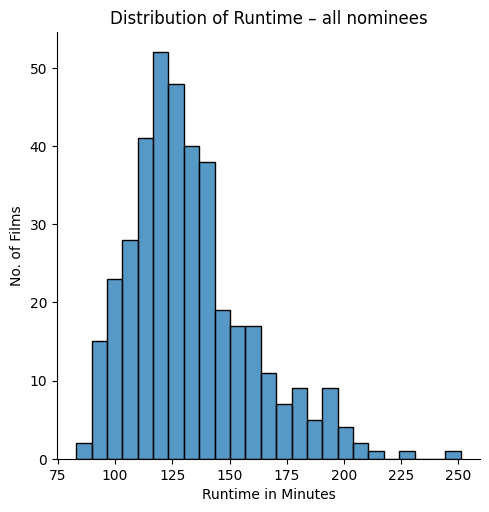

In [ ]:
# Runtime - histogram
# all nominees

plt.figure(figsize=(12,8), dpi = 300)

ax = sns.displot(x="Runtime", data=pic_df, bins = 25)

ax.set(xlabel='Runtime in Minutes',
       ylabel='No. of Films',
       title='Distribution of Runtime – all nominees')

plt.show()

<Figure size 3600x2400 with 0 Axes>

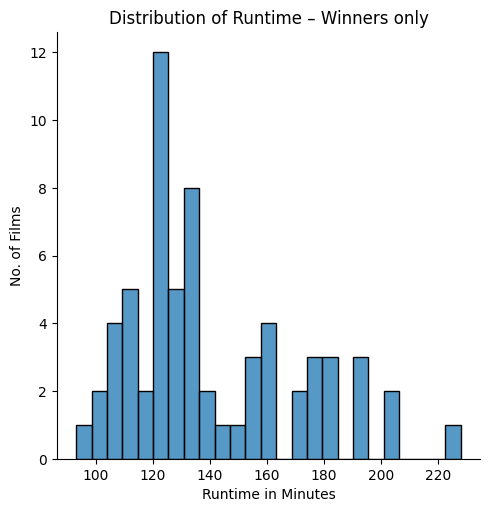

In [ ]:
# # Runtime - histogram
# Winners only – for comparison

plt.figure(figsize=(12,8), dpi = 300)

ax = sns.displot(x="Runtime", data=pic_winners_df, bins = 25)

ax.set(xlabel='Runtime in Minutes',
       ylabel='No. of Films',
       title='Distribution of Runtime – Winners only')

plt.show()

In [ ]:
# still a peak around the 2 hour mark but less normally distributed than all nominees

/tmp/ipython-input-2006934335.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='Produced in America?',


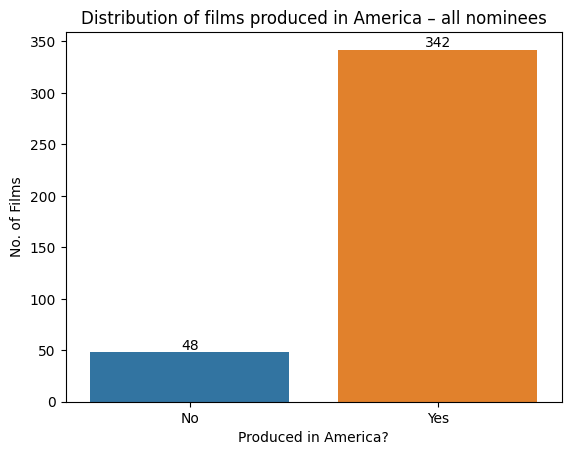

In [ ]:
# Produced in America – bar chart
# all nominees

#plt.figure(figsize=(8,6), dpi = 300)

ax = sns.countplot(x = 'Produced_America',
                   data=pic_df,
                   hue='Produced_America',
                   legend=False)

ax.set(xlabel='Produced in America?',
       ylabel='No. of Films',
       title='Distribution of films produced in America – all nominees',
       xticklabels=['No','Yes'])

for container in ax.containers:
    ax.bar_label(container)

plt.show()

/tmp/ipython-input-2459147337.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='Produced in America?',


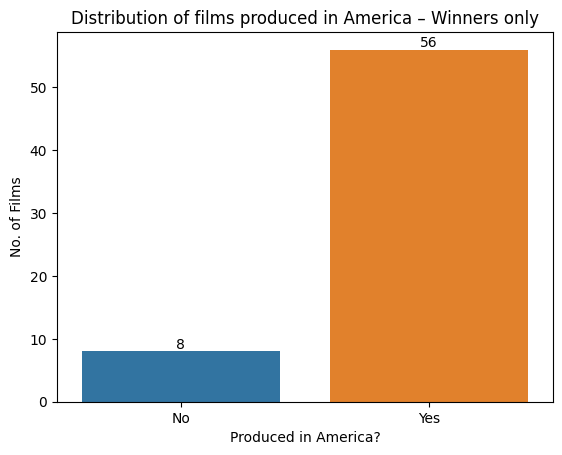

In [ ]:
# Produced in America – bar chart
# winners only

#plt.figure(figsize=(8,6), dpi = 300)

ax = sns.countplot(x = 'Produced_America',
                   data=pic_winners_df,
                   hue='Produced_America',
                   legend=False)

ax.set(xlabel='Produced in America?',
       ylabel='No. of Films',
       title='Distribution of films produced in America – Winners only',
       xticklabels=['No','Yes'])

for container in ax.containers:
    ax.bar_label(container)

plt.show()

In [ ]:
# basically the same ratio

/tmp/ipython-input-2969952303.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='English spoken?',


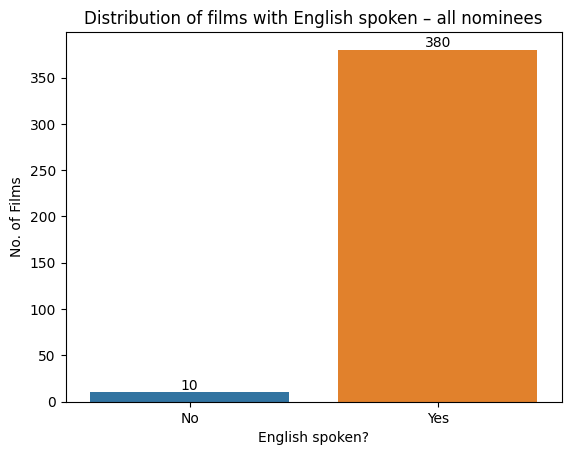

In [ ]:
# English_spoken – bar chart
# all nominees

#plt.figure(figsize=(8,6), dpi = 300)

ax = sns.countplot(x = 'English_spoken',
                   data=pic_df,
                   hue='English_spoken',
                   legend=False)

ax.set(xlabel='English spoken?',
       ylabel='No. of Films',
       title='Distribution of films with English spoken – all nominees',
       xticklabels=['No','Yes'])

for container in ax.containers:
    ax.bar_label(container)

plt.show()

/tmp/ipython-input-576530854.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='English spoken?',


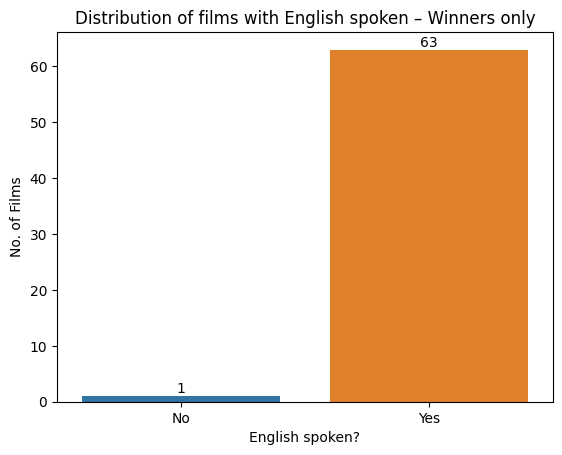

In [ ]:
# English_spoken – bar chart
# Winners only

#plt.figure(figsize=(8,6), dpi = 300)

ax = sns.countplot(x = 'English_spoken',
                   data=pic_winners_df,
                   hue='English_spoken',
                   legend=False)

ax.set(xlabel='English spoken?',
       ylabel='No. of Films',
       title='Distribution of films with English spoken – Winners only',
       xticklabels=['No','Yes'])

for container in ax.containers:
    ax.bar_label(container)

plt.show()

In [ ]:
# only 1 Best Picture winner since 1961 where English isn't spoken

pic_winners_df[pic_winners_df['English_spoken'] == 0]

,Film,Oscar_Year,Winner,Total_Oscar_noms,Oscar_nom_director,Rating_IMDB,Rating_rtaudience,Rating_rtcritic,Release_Q1,Release_Q2,...,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Runtime,Produced_America,English_spoken,Best_Editing_Nom
265,The Artist,2012,1,10,1,7.9,87,96,1,0,...,0,0,0,1,0,0,100,0,0,1


In [ ]:
# Parasite should be included? But has a 1 (yes) in the English_spoken column when it shouldn't

pic_winners_df[pic_winners_df['Film'] == 'Parasite']

,Film,Oscar_Year,Winner,Total_Oscar_noms,Oscar_nom_director,Rating_IMDB,Rating_rtaudience,Rating_rtcritic,Release_Q1,Release_Q2,...,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Runtime,Produced_America,English_spoken,Best_Editing_Nom
341,Parasite,2020,1,6,1,8.6,93,99,0,0,...,0,0,0,0,0,0,133,0,1,1


In [ ]:
# deciding to drop English_spoken – sparked because of seemingly erroneous data, confirmed because of huge imbalance

pic_df = pic_df.drop(['English_spoken'], axis=1)
pic_winners_df = pic_winners_df.drop(['English_spoken'], axis=1)

/tmp/ipython-input-2139527646.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='Best Editing Oscar nomination?',


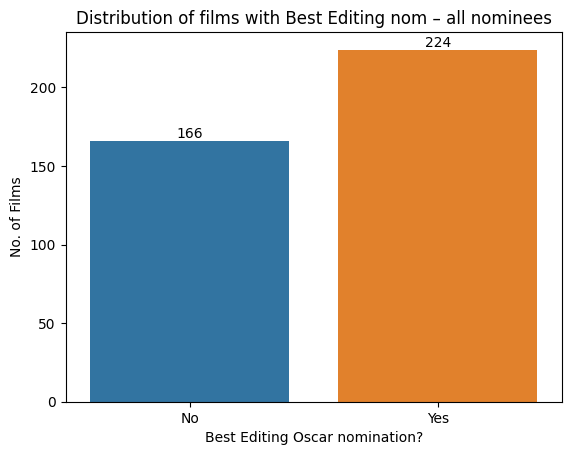

In [ ]:
# Best Editing nom – bar chart
# all nominees

#plt.figure(figsize=(8,6), dpi = 300)

ax = sns.countplot(x = 'Best_Editing_Nom',
                   data=pic_df,
                   hue='Best_Editing_Nom',
                   legend=False)

ax.set(xlabel='Best Editing Oscar nomination?',
       ylabel='No. of Films',
       title='Distribution of films with Best Editing nom – all nominees',
       xticklabels=['No','Yes'])

for container in ax.containers:
    ax.bar_label(container)

plt.show()

/tmp/ipython-input-752309169.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='Best Editing Oscar nomination?',


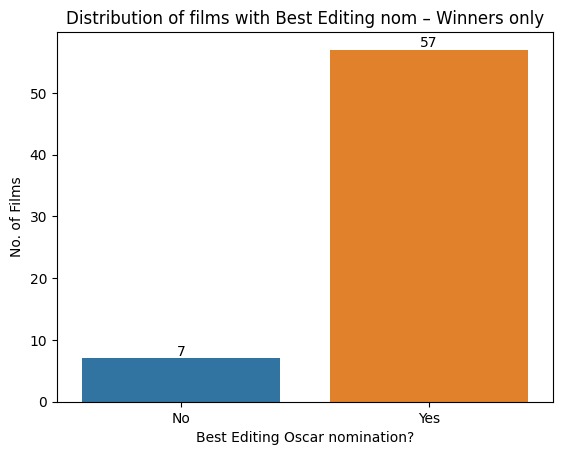

In [ ]:
# Best Editing nom – bar chart
# Winners only

#plt.figure(figsize=(8,6), dpi = 300)

ax = sns.countplot(x = 'Best_Editing_Nom',
                   data=pic_winners_df,
                   hue='Best_Editing_Nom',
                   legend=False)

ax.set(xlabel='Best Editing Oscar nomination?',
       ylabel='No. of Films',
       title='Distribution of films with Best Editing nom – Winners only',
       xticklabels=['No','Yes'])

for container in ax.containers:
    ax.bar_label(container)

plt.show()

In [ ]:
# far bigger % of winners have best editing nomination compared to general nominees dataset
# definitely need to keep in the dataset

### BEST DIRECTOR - NEW FEATURES

New features I want to add for Best Director:

Prev_Oscar_dir_nom_binary

Prev_Oscar_dir_win_binary

American

Gender

Age


In [ ]:
dir_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 325 entries, 0 to 324
Data columns (total 48 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Film                 325 non-null    object 
 1   Oscar_Year           325 non-null    int64  
 2   Nominee              325 non-null    object 
 3   Winner               325 non-null    int64  
 4   Prev_Oscar_dir_noms  325 non-null    int64  
 5   Prev_Oscar_dir_wins  325 non-null    int64  
 6   Oscar_nom_picture    325 non-null    int64  
 7   Total_Oscar_noms     325 non-null    int64  
 8   Rating_IMDB          325 non-null    float64
 9   Rating_rtaudience    325 non-null    int64  
 10  Rating_rtcritic      325 non-null    int64  
 11  Release_Q1           325 non-null    int64  
 12  Release_Q2           325 non-null    int64  
 13  Release_Q3           325 non-null    int64  
 14  Release_Q4           325 non-null    int64  
 15  BAFTA_Nom            325 non-null    int

In [ ]:
# renaming Prev_Oscar_dir_noms column to include 'count' for clarity

dir_df.rename(columns={'Prev_Oscar_dir_noms': 'Prev_Oscar_dir_noms_count', 'Prev_Oscar_dir_wins':'Prev_Oscar_dir_wins_count'}, inplace=True)

dir_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 325 entries, 0 to 324
Data columns (total 48 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Film                       325 non-null    object 
 1   Oscar_Year                 325 non-null    int64  
 2   Nominee                    325 non-null    object 
 3   Winner                     325 non-null    int64  
 4   Prev_Oscar_dir_noms_count  325 non-null    int64  
 5   Prev_Oscar_dir_wins_count  325 non-null    int64  
 6   Oscar_nom_picture          325 non-null    int64  
 7   Total_Oscar_noms           325 non-null    int64  
 8   Rating_IMDB                325 non-null    float64
 9   Rating_rtaudience          325 non-null    int64  
 10  Rating_rtcritic            325 non-null    int64  
 11  Release_Q1                 325 non-null    int64  
 12  Release_Q2                 325 non-null    int64  
 13  Release_Q3                 325 non-null    int64  

In [ ]:
# Prev_Oscar_dir_nom_bin / Prev_Oscar_dir_win_bin – binary value for if the director has been nominated/won a Directing Oscar previously
# Look at Prev_Oscar_dir_noms/wins_count column and if 1 or more, put 1 in new column

dir_df['Prev_Oscar_dir_nom_bin'] = np.where(dir_df['Prev_Oscar_dir_noms_count'] >= 1, 1, 0)
dir_df['Prev_Oscar_dir_win_bin'] = np.where(dir_df['Prev_Oscar_dir_wins_count'] >= 1, 1, 0)

In [ ]:
# Age – requires web scraper

# Downloaded IMDB person tsv file from their non-commercial datasets
# Reference: https://datasets.imdbws.com/

# Using function to extract birth year and calculate age at the Oscar ceremony
# Reference: Claude.ai

# install necessary packages
!pip install gdown
import gdown

# Download the file first
print("Downloading IMDb dataset...")
file_id = '17yH0kwsk6mwjNc9SnESqKJzLJo4p5LTd'
url = f'https://drive.google.com/uc?id={file_id}'
output_path = 'name.basics.tsv'

# Download the file
gdown.download(url, output_path, quiet=False)

# Then load it
print("Loading IMDb dataset...")
imdb_data = pd.read_csv(
    output_path,
    sep='\t',
    dtype={'birthYear': 'Int64'},
    na_values=['\\N']
)

# Filter for directors only and select relevant columns
directors_imdb = imdb_data[
    imdb_data['primaryProfession'].str.contains('director', case=False, na=False)
][['primaryName', 'birthYear']].copy()

# Remove duplicates (keep first occurrence)
directors_imdb = directors_imdb.drop_duplicates(subset=['primaryName'])

print(f"Found {len(directors_imdb):,} unique directors in IMDb dataset")

# Join with your directors DataFrame
print("Joining with Oscar directors...")
dir_ages = dir_df.merge(
    directors_imdb,
    left_on='Nominee',
    right_on='primaryName',
    how='left'
)

# Calculate age at ceremony
dir_ages['Age_at_Ceremony'] = dir_ages['Oscar_Year'] - dir_ages['birthYear']

# Clean up - drop the extra primaryName column
dir_ages = dir_ages.drop('primaryName', axis=1)

# Print summary
total = len(dir_ages)
matched = dir_ages['birthYear'].notna().sum()
print(f"\nMatching Summary:")
print(f"Total nominations: {total}")
print(f"Birth years found: {matched} ({matched/total*100:.1f}%)")

if matched > 0:
    print(f"Average age at ceremony: {dir_ages['Age_at_Ceremony'].mean():.1f}")
    print(f"Age range: {dir_ages['Age_at_Ceremony'].min():.0f} - {dir_ages['Age_at_Ceremony'].max():.0f}")

# Show unmatched directors
unmatched = dir_ages[dir_ages['birthYear'].isna()]['Nominee'].unique()
if len(unmatched) > 0:
    print(f"\nUnmatched directors ({len(unmatched)} total):")
    for director in unmatched[:10]:
        print(f"- {director}")
    if len(unmatched) > 10:
        print(f"... and {len(unmatched) - 10} more")

print(f"\nResult stored in 'dir_ages' DataFrame")

Downloading...
From (original): https://drive.google.com/uc?id=17yH0kwsk6mwjNc9SnESqKJzLJo4p5LTd
From (redirected): https://drive.google.com/uc?id=17yH0kwsk6mwjNc9SnESqKJzLJo4p5LTd&confirm=t&uuid=3a31ef23-9558-400b-8ceb-507efe95152d
To: /content/name.basics.tsv
100%|██████████| 895M/895M [00:06<00:00, 128MB/s]


Loading IMDb dataset...
Found 1,063,833 unique directors in IMDb dataset
Joining with Oscar directors...

Matching Summary:
Total nominations: 325
Birth years found: 294 (90.5%)
Average age at ceremony: 50.4
Age range: 24 - 82

Unmatched directors (23 total):
- Costa Gavras
- Franois Truffaut
- Milo Forman
- Lina Wertmller
- Warren Beatty
- douard Molinaro
- James L. Brooks
- Roland Joff
- Hctor Babenco
- Lasse Hallstrm
... and 13 more

Result stored in 'dir_ages' DataFrame


In [ ]:
# Looking at results df
dir_ages

,Film,Oscar_Year,Nominee,Winner,Prev_Oscar_dir_noms_count,Prev_Oscar_dir_wins_count,Oscar_nom_picture,Total_Oscar_noms,Rating_IMDB,Rating_rtaudience,...,MPAA_PG-13,MPAA_R,MPAA_NC-17,Runtime,Produced_America,English_spoken,Prev_Oscar_dir_nom_bin,Prev_Oscar_dir_win_bin,birthYear,Age_at_Ceremony
0,The Apartment,1961,Billy Wilder,1,0,0,1,10,8.3,94,...,0,0,0,125,1,1,0,0,1906,55
1,Sons and Lovers,1961,Jack Cardiff,0,0,0,1,7,7.3,54,...,0,0,0,103,0,1,0,0,1914,47
2,Never on Sunday,1961,Jules Dassin,0,0,0,0,4,7.4,83,...,0,0,0,91,0,1,0,0,1911,50
3,Psycho,1961,Alfred Hitchcock,0,0,0,0,4,8.5,94,...,0,1,0,109,1,1,0,0,1899,62
4,The Sundowners,1961,Fred Zinnemann,0,0,0,1,5,7.2,62,...,0,0,0,133,1,1,0,0,1907,54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
320,Anora,2025,Sean Baker,1,0,0,1,6,7.8,90,...,0,1,0,139,1,1,0,0,<NA>,<NA>
321,The Brutalist,2025,Brady Corbet,0,0,0,1,10,8.0,81,...,0,1,0,215,1,1,0,0,1988,37
322,A Complete Unknown,2025,James Mangold,0,0,0,1,8,7.7,96,...,0,1,0,140,1,1,0,0,1963,62
323,Emilia Perez,2025,Jacques Audiard,0,0,0,1,13,5.9,19,...,0,1,0,132,1,1,0,0,1952,73


In [ ]:
# looking at unmatched directors
unmatched

array(['Costa Gavras', 'Franois Truffaut', 'Milo Forman',
       'Lina Wertmller', 'Warren Beatty', 'douard Molinaro',
       'James L. Brooks', 'Roland Joff', 'Hctor Babenco',
       'Lasse Hallstrm', 'Kevin Costner', 'Krzysztof Kielowski',
       'Quentin Tarantino', 'Anthony Minghella', 'Ron Howard',
       'Pedro Almodvar', 'Paul Haggis', 'Tom McCarthy', 'Bong Joon-ho',
       'Ryusuke Hamaguchi', 'Daniel Kwan, Daniel Scheinert', 'Todd Field',
       'Sean Baker'], dtype=object)

In [ ]:
# can see that a lot of them were missed because of incorrect spellings/missing characters
# correcting those, and combining the Daniels

corrections = {
    'Franois Truffaut': 'Francois Truffaut',
    'Milo Forman': 'Milos Forman',
    'Lina Wertmller': 'Lina Wertmuller',
    'douard Molinaro': 'Edouard Molinaro',
    'Roland Joff': 'Roland Joffe',
    'Hctor Babenco': 'Hector Babenco',
    'Lasse Hallstrm': 'Lasse Hallstrom',
    'Krzysztof Kielowski': 'Krzysztof Kieslowski',
    'Pedro Almodvar': 'Pedro Almodovar',
    'Daniel Kwan, Daniel Scheinert': 'Daniels'
}

dir_ages['Nominee'] = dir_ages['Nominee'].replace(corrections)

In [ ]:
# checking no. of missing birth year values

dir_ages['birthYear'].isna().sum()

np.int64(31)

In [ ]:
# filling in missing birth years according to Nominee name

nom_birthyears = {
    'Costa Gavras': 1933,
    'Francois Truffaut': 1932,
    'Milos Forman': 1932,
    'Lina Wertmuller': 1928,
    'Warren Beatty': 1937,
    'Edouard Molinaro': 1928,
    'James L. Brooks': 1940,
    'Roland Joffe': 1945,
    'Hector Babenco': 1946,
    'Lasse Hallstrom': 1946,
    'Kevin Costner': 1955,
    'Krzysztof Kieslowski': 1941,
    'Quentin Tarantino': 1963,
    'Anthony Minghella': 1954,
    'Ron Howard': 1954,
    'Pedro Almodovar': 1949,
    'Paul Haggis': 1953,
    'Alejandro G. Inarritu': 1963,
    'Tom McCarthy': 1966,
    'Alfonso Cuaron': 1961,
    'Chloe Zhao': 1982,
    'Bong Joon-ho': 1969,
    'Ryusuke Hamaguchi': 1978,
    'Daniels': 1987,
    'Todd Field': 1964,
    'Ruben Ostlund': 1974,
    'Sean Baker': 1971
}

dir_ages['birthYear'] = dir_ages['birthYear'].fillna(dir_ages['Nominee'].map(nom_birthyears))

In [ ]:
# checking missing values, should be 0

dir_ages['birthYear'].isna().sum()

np.int64(0)

In [ ]:
# checking missing Age_at_Ceremony values

dir_ages['Age_at_Ceremony'].isna().sum()

np.int64(31)

In [ ]:
# filling by subtracting the birth year from the Oscar year
# aware this doesn't account for birth month, will test that shortly

dir_ages['Age_at_Ceremony'] = dir_ages['Age_at_Ceremony'].fillna(dir_ages['Oscar_Year'] - dir_ages['birthYear'])

In [ ]:
# checking again, should be 0

dir_ages['Age_at_Ceremony'].isna().sum()

np.int64(0)

In [ ]:
# Testing whether not accounting for birth month affects precision for Age at Ceremony feature
# Reference: Claude.ai

# Add random ±0.5 year noise and see correlation
age_with_noise = dir_ages['Age_at_Ceremony'] + np.random.uniform(-0.5, 0.5, len(dir_ages))
correlation = np.corrcoef(dir_ages['Age_at_Ceremony'], age_with_noise)[0,1]

# Should be very high (>0.99), if so precision level is fine

correlation

np.float64(0.9996322052998754)

In [ ]:
# drop the birthYear column, no longer needed

dir_ages.drop(['birthYear'], axis=1)

,Film,Oscar_Year,Nominee,Winner,Prev_Oscar_dir_noms_count,Prev_Oscar_dir_wins_count,Oscar_nom_picture,Total_Oscar_noms,Rating_IMDB,Rating_rtaudience,...,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Runtime,Produced_America,English_spoken,Prev_Oscar_dir_nom_bin,Prev_Oscar_dir_win_bin,Age_at_Ceremony
0,The Apartment,1961,Billy Wilder,1,0,0,1,10,8.3,94,...,0,0,0,0,125,1,1,0,0,55
1,Sons and Lovers,1961,Jack Cardiff,0,0,0,1,7,7.3,54,...,0,0,0,0,103,0,1,0,0,47
2,Never on Sunday,1961,Jules Dassin,0,0,0,0,4,7.4,83,...,0,0,0,0,91,0,1,0,0,50
3,Psycho,1961,Alfred Hitchcock,0,0,0,0,4,8.5,94,...,0,0,1,0,109,1,1,0,0,62
4,The Sundowners,1961,Fred Zinnemann,0,0,0,1,5,7.2,62,...,0,0,0,0,133,1,1,0,0,54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
320,Anora,2025,Sean Baker,1,0,0,1,6,7.8,90,...,0,0,1,0,139,1,1,0,0,54
321,The Brutalist,2025,Brady Corbet,0,0,0,1,10,8.0,81,...,0,0,1,0,215,1,1,0,0,37
322,A Complete Unknown,2025,James Mangold,0,0,0,1,8,7.7,96,...,0,0,1,0,140,1,1,0,0,62
323,Emilia Perez,2025,Jacques Audiard,0,0,0,1,13,5.9,19,...,0,0,1,0,132,1,1,0,0,73


In [ ]:
# using a Wikidata scraper for features on gender and birth country
# Reference: Claude.ai

import requests
import time
import json
from urllib.parse import quote

class ComprehensiveWikidataScraper:
    def __init__(self):
        self.base_url = "https://www.wikidata.org/w/api.php"
        self.sparql_url = "https://query.wikidata.org/sparql"

    def search_person(self, name):
        """Search for a person on Wikidata and return their entity ID"""
        try:
            # Try different name variations
            name_variations = [
                name,
                name.replace('ö', 'o').replace('ä', 'a').replace('ü', 'u'),  # Remove umlauts
                name.replace('é', 'e').replace('è', 'e').replace('á', 'a'),  # Remove accents
            ]

            for name_variant in name_variations:
                params = {
                    'action': 'wbsearchentities',
                    'search': name_variant,
                    'language': 'en',
                    'type': 'item',
                    'limit': 10,
                    'format': 'json'
                }

                response = requests.get(self.base_url, params=params, timeout=15)

                # Handle rate limiting with exponential backoff
                retry_count = 0
                while response.status_code == 429 and retry_count < 3:
                    wait_time = (2 ** retry_count) * 3  # 3, 6, 12 seconds
                    print(f"  Rate limited, waiting {wait_time} seconds... (attempt {retry_count + 1})")
                    time.sleep(wait_time)
                    retry_count += 1

                    response = requests.get(self.base_url, params=params, timeout=15)

                if response.status_code != 200:
                    continue

                data = response.json()

                # Look for any person in entertainment industry
                for item in data.get('search', []):
                    entity_id = item['id']
                    description = item.get('description', '').lower()

                    # Check if it's a film-related person
                    if any(keyword in description for keyword in ['director', 'filmmaker', 'film', 'movie', 'cinema']):
                        return entity_id, item.get('description', '')

                    # Also check if they have director occupation
                    if self.is_film_director(entity_id):
                        return entity_id, item.get('description', '')

                # Small delay between name variations
                time.sleep(1)

            return None, None

        except requests.exceptions.RequestException as e:
            print(f"Request error searching for {name}: {e}")
            return None, None
        except Exception as e:
            print(f"Error searching for {name}: {e}")
            return None, None

    def is_film_director(self, entity_id):
        """Check if the entity is a film director or related film professional"""
        try:
            sparql_query = f"""
            SELECT ?item WHERE {{
              {{ wd:{entity_id} wdt:P106 wd:Q2526255 . }}  # film director
              UNION
              {{ wd:{entity_id} wdt:P106 wd:Q3455803 . }}  # director
              UNION
              {{ wd:{entity_id} wdt:P106 wd:Q1053574 . }}  # filmmaker
              UNION
              {{ wd:{entity_id} wdt:P106 wd:Q28389 . }}    # screenwriter (often directors too)
            }}
            """

            headers = {'Accept': 'application/sparql-results+json'}
            response = requests.get(
                self.sparql_url,
                params={'query': sparql_query},
                headers=headers,
                timeout=10
            )

            if response.status_code == 200:
                data = response.json()
                return len(data['results']['bindings']) > 0

            return False

        except:
            return False

    def get_demographic_data(self, entity_id):
        """Get birth country and gender in one query"""
        if not entity_id:
            return None, None

        try:
            sparql_query = f"""
            SELECT ?countryLabel ?genderLabel WHERE {{
              OPTIONAL {{
                wd:{entity_id} wdt:P19 ?birthPlace .     # place of birth
                ?birthPlace wdt:P17 ?country .           # country
              }}
              OPTIONAL {{ wd:{entity_id} wdt:P21 ?gender . }}      # sex or gender
              SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en" . }}
            }}
            LIMIT 1
            """

            headers = {'Accept': 'application/sparql-results+json'}
            response = requests.get(
                self.sparql_url,
                params={'query': sparql_query},
                headers=headers,
                timeout=15
            )

            # Handle rate limiting with exponential backoff
            retry_count = 0
            while response.status_code == 429 and retry_count < 3:
                wait_time = (2 ** retry_count) * 5  # 5, 10, 20 seconds
                print(f"    SPARQL rate limited, waiting {wait_time} seconds... (attempt {retry_count + 1})")
                time.sleep(wait_time)
                retry_count += 1

                response = requests.get(
                    self.sparql_url,
                    params={'query': sparql_query},
                    headers=headers,
                    timeout=15
                )

            if response.status_code == 200:
                data = response.json()
                results = data['results']['bindings']

                country = None
                gender = None

                if results and len(results) > 0:
                    result = results[0]
                    if 'countryLabel' in result:
                        country = result['countryLabel']['value']
                    if 'genderLabel' in result:
                        gender = result['genderLabel']['value']

                return country, gender

            return None, None

        except requests.exceptions.RequestException as e:
            print(f"Request error getting data for {entity_id}: {e}")
            return None, None
        except Exception as e:
            print(f"Error getting data for {entity_id}: {e}")
            return None, None

    def is_american(self, country):
        """Determine if a country indicates American citizenship"""
        if not country:
            return None

        american_indicators = [
            'United States of America',
            'United States',
            'USA',
            'US'
        ]

        return country in american_indicators

    def standardize_gender(self, gender):
        """Standardize gender values"""
        if not gender:
            return None

        gender_lower = gender.lower()

        if gender_lower in ['male', 'man']:
            return 'Male'
        elif gender_lower in ['female', 'woman']:
            return 'Female'
        elif gender_lower in ['non-binary', 'nonbinary', 'genderqueer', 'genderfluid']:
            return 'Non-binary'
        else:
            return gender

    def process_directors(self, df):
        """Process all directors in the dataframe"""
        unique_directors = df['Nominee'].unique()
        director_data = {}

        print(f"Processing {len(unique_directors)} unique directors...")

        for i, director in enumerate(unique_directors):
            if i % 10 == 0:
                print(f"Progress: {i}/{len(unique_directors)} ({i/len(unique_directors)*100:.1f}%)")

            # Search for director
            entity_id, description = self.search_person(director)

            if entity_id:
                # Get demographic data
                birth_country, gender = self.get_demographic_data(entity_id)
                is_american = self.is_american(birth_country)
                gender_std = self.standardize_gender(gender)

                director_data[director] = {
                    'wikidata_id': entity_id,
                    'description': description,
                    'birth_country': birth_country,
                    'is_american': is_american,
                    'gender_raw': gender,
                    'gender': gender_std
                }

                print(f"  {director}: {birth_country}, {gender}")
            else:
                director_data[director] = {
                    'wikidata_id': None,
                    'description': None,
                    'birth_country': None,
                    'is_american': None,
                    'gender_raw': None,
                    'gender': None
                }
                print(f"  {director}: Not found")

            # Dynamic delay based on progress to avoid rate limits at the end
            if i < len(unique_directors) * 0.5:  # First half
                time.sleep(2)
            elif i < len(unique_directors) * 0.8:  # Next 30%
                time.sleep(3)
            else:  # Last 20% - slower to avoid rate limits
                time.sleep(5)
                print(f"    Using slower pace for final directors...")

        return director_data

    def create_output_dataframe(self, df, director_data):
        """Create the output dataframe with demographic information"""
        result_df = df.copy()

        # Add new columns
        result_df['Wikidata_ID'] = None
        result_df['Wikidata_Description'] = None
        result_df['Birth_Country'] = None
        result_df['Is_American'] = None
        result_df['Gender_Raw'] = None
        result_df['Gender'] = None

        # Apply the data
        for idx, row in result_df.iterrows():
            director = row['Nominee']
            if director in director_data:
                data = director_data[director]
                result_df.at[idx, 'Wikidata_ID'] = data['wikidata_id']
                result_df.at[idx, 'Wikidata_Description'] = data['description']
                result_df.at[idx, 'Birth_Country'] = data['birth_country']
                result_df.at[idx, 'Is_American'] = data['is_american']
                result_df.at[idx, 'Gender_Raw'] = data['gender_raw']
                result_df.at[idx, 'Gender'] = data['gender']

        return result_df

    def print_demographic_summary(self, df):
        """Print summary statistics"""
        total = len(df)
        found_data = df['Wikidata_ID'].notna().sum()

        print(f"\n=== DEMOGRAPHIC SUMMARY ===")
        print(f"Total nominations: {total}")
        print(f"Directors found in Wikidata: {found_data} ({found_data/total*100:.1f}%)")

        # Country summary
        found_countries = df['Birth_Country'].notna().sum()
        if found_countries > 0:
            american_count = df['Is_American'].sum() if df['Is_American'].notna().any() else 0
            print(f"\nCOUNTRY DATA:")
            print(f"Birth countries found: {found_countries} ({found_countries/total*100:.1f}%)")
            print(f"American directors: {american_count}")
            print(f"Non-American directors: {found_countries - american_count}")

            country_counts = df['Birth_Country'].value_counts().head(5)
            print(f"Top countries: {', '.join([f'{c}: {n}' for c, n in country_counts.items()])}")

        # Gender summary
        found_gender = df['Gender'].notna().sum()
        if found_gender > 0:
            print(f"\nGENDER DATA:")
            print(f"Gender data found: {found_gender} ({found_gender/total*100:.1f}%)")
            gender_counts = df['Gender'].value_counts()
            for gender, count in gender_counts.items():
                print(f"  {gender}: {count}")

        # Show unmatched directors
        unmatched = df[df['Wikidata_ID'].isna()]['Nominee'].unique()
        if len(unmatched) > 0:
            print(f"\n=== UNMATCHED DIRECTORS ({len(unmatched)} total) ===")
            for director in unmatched:
                print(f"- {director}")

# Main function
def get_director_demographics(df):
    """Get birth country and gender data for directors"""
    scraper = ComprehensiveWikidataScraper()

    # Process directors
    director_data = scraper.process_directors(df)

    # Create output dataframe
    result_df = scraper.create_output_dataframe(df, director_data)

    # Print summary
    scraper.print_demographic_summary(result_df)

    return result_df

# Usage for Google Colab
# Assuming your dataframe with ages is called dir_ages
dir_demos = get_director_demographics(dir_ages)

print(f"\nResults stored in 'dir_demos' DataFrame")
print(f"Columns added: Wikidata_ID, Birth_Country, Is_American, Gender, Gender_Raw")

Processing 198 unique directors...
Progress: 0/198 (0.0%)
  Billy Wilder: Poland, male
  Jack Cardiff: United Kingdom, male
  Jules Dassin: United States, male
  Alfred Hitchcock: United Kingdom, male
  Fred Zinnemann: Poland, male
  Robert Wise: United States, male
  Federico Fellini: Italy, male
  Stanley Kramer: United States, male
  Robert Rossen: United States, male
  J. Lee Thompson: United Kingdom, male
Progress: 10/198 (5.1%)
  David Lean: United Kingdom, male
  Pietro Germi: Italy, male
  Robert Mulligan: United States, male
  Arthur Penn: United States, male
  Frank Perry: United States, male
  Tony Richardson: United Kingdom, male
  Elia Kazan: Turkey, male
  Otto Preminger: Ukraine, male
  Martin Ritt: United States, male
  George Cukor: United States, male
Progress: 20/198 (10.1%)
  Michael Cacoyannis: Cyprus, male
  Peter Glenville: United Kingdom, male
  Stanley Kubrick: United States, male
  Robert Stevenson: United Kingdom, male
  John Schlesinger: United Kingdom, male

In [ ]:
dir_demos

,Film,Oscar_Year,Nominee,Winner,Prev_Oscar_dir_noms_count,Prev_Oscar_dir_wins_count,Oscar_nom_picture,Total_Oscar_noms,Rating_IMDB,Rating_rtaudience,...,Prev_Oscar_dir_nom_bin,Prev_Oscar_dir_win_bin,birthYear,Age_at_Ceremony,Wikidata_ID,Wikidata_Description,Birth_Country,Is_American,Gender_Raw,Gender
0,The Apartment,1961,Billy Wilder,1,0,0,1,10,8.3,94,...,0,0,1906,55,Q51547,Austrian-born American filmmaker and screenwri...,Poland,False,male,Male
1,Sons and Lovers,1961,Jack Cardiff,0,0,0,1,7,7.3,54,...,0,0,1914,47,Q436704,"British cinematographer, director and photogra...",United Kingdom,False,male,Male
2,Never on Sunday,1961,Jules Dassin,0,0,0,0,4,7.4,83,...,0,0,1911,50,Q260969,American film director (1911–2008),United States,True,male,Male
3,Psycho,1961,Alfred Hitchcock,0,0,0,0,4,8.5,94,...,0,0,1899,62,Q7374,British filmmaker (1899–1980),United Kingdom,False,male,Male
4,The Sundowners,1961,Fred Zinnemann,0,0,0,1,5,7.2,62,...,0,0,1907,54,Q55420,Austrian film director (1907-1997),Poland,False,male,Male
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
320,Anora,2025,Sean Baker,1,0,0,1,6,7.8,90,...,0,0,1971,54,Q7441419,American film director,United States,True,male,Male
321,The Brutalist,2025,Brady Corbet,0,0,0,1,10,8.0,81,...,0,0,1988,37,Q897115,American actor,United States,True,male,Male
322,A Complete Unknown,2025,James Mangold,0,0,0,1,8,7.7,96,...,0,0,1963,62,Q433893,"American film director, screenwriter",United States,True,male,Male
323,Emilia Perez,2025,Jacques Audiard,0,0,0,1,13,5.9,19,...,0,0,1952,73,Q382389,French film director and screenwriter,France,False,male,Male


In [ ]:
# renaming Is_American column to Born_in_America for clarity
dir_demos.rename(columns={'Is_American': 'Born_in_America'}, inplace=True)

In [ ]:
# checking missing values
dir_demos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 325 entries, 0 to 324
Data columns (total 58 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Film                       325 non-null    object 
 1   Oscar_Year                 325 non-null    int64  
 2   Nominee                    325 non-null    object 
 3   Winner                     325 non-null    int64  
 4   Prev_Oscar_dir_noms_count  325 non-null    int64  
 5   Prev_Oscar_dir_wins_count  325 non-null    int64  
 6   Oscar_nom_picture          325 non-null    int64  
 7   Total_Oscar_noms           325 non-null    int64  
 8   Rating_IMDB                325 non-null    float64
 9   Rating_rtaudience          325 non-null    int64  
 10  Rating_rtcritic            325 non-null    int64  
 11  Release_Q1                 325 non-null    int64  
 12  Release_Q2                 325 non-null    int64  
 13  Release_Q3                 325 non-null    int64  

In [ ]:
# 1x missing values on new features
# think might be all same row

dir_demos[dir_demos[['Born_in_America', 'Gender']].isna().any(axis=1)]

,Film,Oscar_Year,Nominee,Winner,Prev_Oscar_dir_noms_count,Prev_Oscar_dir_wins_count,Oscar_nom_picture,Total_Oscar_noms,Rating_IMDB,Rating_rtaudience,...,Prev_Oscar_dir_nom_bin,Prev_Oscar_dir_win_bin,birthYear,Age_at_Ceremony,Wikidata_ID,Wikidata_Description,Birth_Country,Born_in_America,Gender_Raw,Gender
310,Everything Everywhere All at Once,2023,Daniels,1,0,0,1,11,7.8,79,...,0,0,1987,36,Q30122828,American filmmakers,None,None,None,None


In [ ]:
# Daniels couldn't be found because is two directors combined (Daniel Kwan and Daniel Scheinert, 'Everything Everywhere All At Once')
# adding manually

dir_demos.loc[dir_demos.index == 310, ['Born_in_America', 'Gender']] = [
    1, 'Male'
]

In [ ]:
# converting Born_in_America column to binary 1s and 0s

dir_demos['Born_in_America'] = dir_demos['Born_in_America'].astype(int)

In [ ]:
# dropping columns not needed and renaming back to dir_df
dir_df = dir_demos.drop(['birthYear', 'Wikidata_ID', 'Wikidata_Description', 'Birth_Country', 'Gender_Raw'], axis=1)

In [ ]:
dir_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 325 entries, 0 to 324
Data columns (total 53 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Film                       325 non-null    object 
 1   Oscar_Year                 325 non-null    int64  
 2   Nominee                    325 non-null    object 
 3   Winner                     325 non-null    int64  
 4   Prev_Oscar_dir_noms_count  325 non-null    int64  
 5   Prev_Oscar_dir_wins_count  325 non-null    int64  
 6   Oscar_nom_picture          325 non-null    int64  
 7   Total_Oscar_noms           325 non-null    int64  
 8   Rating_IMDB                325 non-null    float64
 9   Rating_rtaudience          325 non-null    int64  
 10  Rating_rtcritic            325 non-null    int64  
 11  Release_Q1                 325 non-null    int64  
 12  Release_Q2                 325 non-null    int64  
 13  Release_Q3                 325 non-null    int64  

In [ ]:
# writing complete dir_df to csv

dir_df_existing_path = '/content/drive/My Drive/MY STUFF/MSC/DISSERTATION/SHARED FOR NOTEBOOK/bestdirector_data_complete.csv'

dir_df.to_csv(dir_df_existing_path, index=False, header=True, sep=',', encoding='utf-8')

### NEW DIRECTOR FEATURES – VISUALISATIONS

In [ ]:
# create df of Best Director winners, for visualisations

dir_winners_df = dir_df[dir_df['Winner'] == 1]

dir_winners_df

,Film,Oscar_Year,Nominee,Winner,Prev_Oscar_dir_noms_count,Prev_Oscar_dir_wins_count,Oscar_nom_picture,Total_Oscar_noms,Rating_IMDB,Rating_rtaudience,...,MPAA_R,MPAA_NC-17,Runtime,Produced_America,English_spoken,Prev_Oscar_dir_nom_bin,Prev_Oscar_dir_win_bin,Age_at_Ceremony,Born_in_America,Gender
0,The Apartment,1961,Billy Wilder,1,0,0,1,10,8.3,94,...,0,0,125,1,1,0,0,55,0,Male
5,West Side Story,1962,Robert Wise,1,0,0,1,11,7.6,84,...,0,0,153,1,1,0,0,48,1,Male
10,Lawrence of Arabia,1963,David Lean,1,0,0,1,10,8.3,93,...,0,0,228,0,1,0,0,55,0,Male
15,Tom Jones,1964,Tony Richardson,1,0,0,1,10,6.7,58,...,0,0,128,0,1,0,0,36,0,Male
19,My Fair Lady,1965,George Cukor,1,0,0,1,12,7.9,90,...,0,0,170,1,1,0,0,66,1,Male
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
303,Parasite,2020,Bong Joon-ho,1,0,0,1,6,8.6,93,...,0,0,133,0,1,0,0,51,0,Male
307,The Power of the Dog,2022,Jane Campion,1,1,0,1,12,6.9,79,...,1,0,127,0,1,1,0,68,0,Female
310,Everything Everywhere All at Once,2023,Daniels,1,0,0,1,11,7.8,79,...,1,0,140,1,1,0,0,36,1,Male
317,Oppenheimer,2024,Christopher Nolan,1,1,0,1,1,8.3,91,...,1,0,181,1,1,1,0,54,0,Male


/tmp/ipython-input-956277884.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='Previous Directing Oscar nomination?',


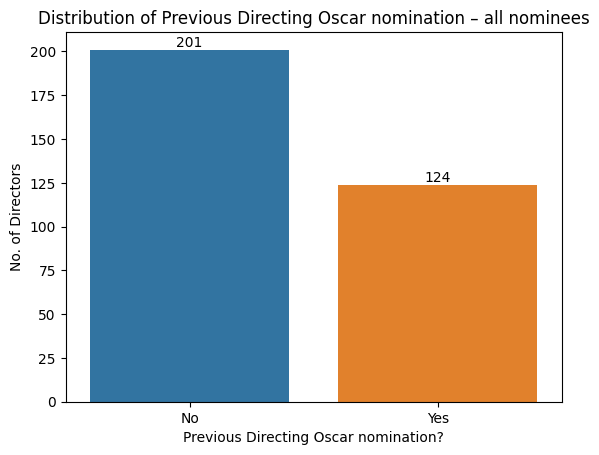

In [ ]:
# Previous Directing Oscar nom (binary)
# bar chart
# all nominees

#plt.figure(figsize=(8,6), dpi = 300)

ax = sns.countplot(x = 'Prev_Oscar_dir_nom_bin',
                   data=dir_df,
                   hue='Prev_Oscar_dir_nom_bin',
                   legend=False)

ax.set(xlabel='Previous Directing Oscar nomination?',
       ylabel='No. of Directors',
       title='Distribution of Previous Directing Oscar nomination – all nominees',
       xticklabels=['No','Yes'])

for container in ax.containers:
    ax.bar_label(container)

plt.show()

/tmp/ipython-input-22568617.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='Previous Directing Oscar nomination?',


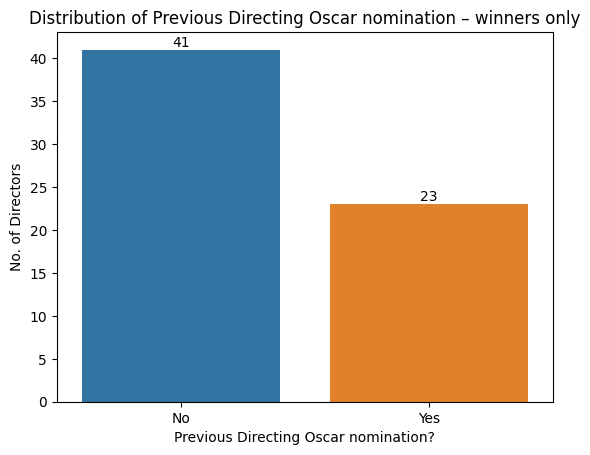

In [ ]:
# Previous Directing Oscar nom (binary)
# bar chart
# winners only

#plt.figure(figsize=(8,6), dpi = 300)

ax = sns.countplot(x = 'Prev_Oscar_dir_nom_bin',
                   data=dir_winners_df,
                   hue='Prev_Oscar_dir_nom_bin',
                   legend=False)

ax.set(xlabel='Previous Directing Oscar nomination?',
       ylabel='No. of Directors',
       title='Distribution of Previous Directing Oscar nomination – winners only',
       xticklabels=['No','Yes'])

for container in ax.containers:
    ax.bar_label(container)

plt.show()

/tmp/ipython-input-2953809934.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='Previous Directing Oscar win?',


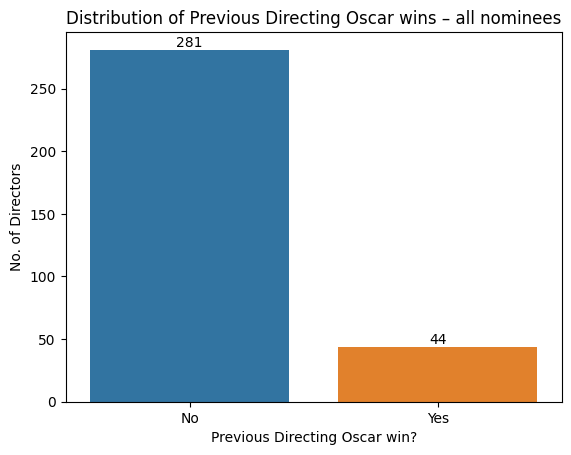

In [ ]:
# Previous Directing Oscar win (binary)
# bar chart
# all nominees

#plt.figure(figsize=(8,6), dpi = 300)

ax = sns.countplot(x = 'Prev_Oscar_dir_win_bin',
                   data=dir_df,
                   hue='Prev_Oscar_dir_win_bin',
                   legend=False)

ax.set(xlabel='Previous Directing Oscar win?',
       ylabel='No. of Directors',
       title='Distribution of Previous Directing Oscar wins – all nominees',
       xticklabels=['No','Yes'])

for container in ax.containers:
    ax.bar_label(container)

plt.show()

/tmp/ipython-input-2495460581.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='Previous Directing Oscar win?',


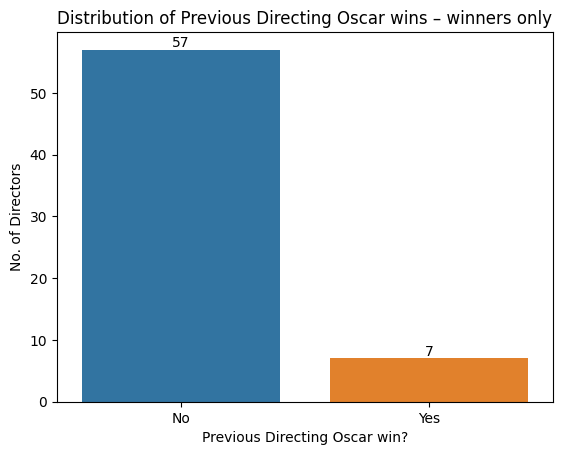

In [ ]:
# Previous Directing Oscar win (binary)
# bar chart
# winners only

#plt.figure(figsize=(8,6), dpi = 300)

ax = sns.countplot(x = 'Prev_Oscar_dir_win_bin',
                   data=dir_winners_df,
                   hue='Prev_Oscar_dir_win_bin',
                   legend=False)

ax.set(xlabel='Previous Directing Oscar win?',
       ylabel='No. of Directors',
       title='Distribution of Previous Directing Oscar wins – winners only',
       xticklabels=['No','Yes'])

for container in ax.containers:
    ax.bar_label(container)

plt.show()

<Figure size 3600x2400 with 0 Axes>

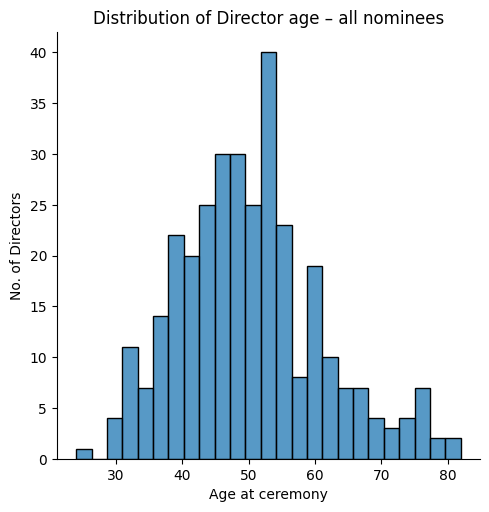

In [ ]:
# Age at ceremony - histogram
# all nominees

plt.figure(figsize=(12,8), dpi = 300)

ax = sns.displot(x="Age_at_Ceremony", data=dir_df, bins = 25)

ax.set(xlabel='Age at ceremony',
       ylabel='No. of Directors',
       title='Distribution of Director age – all nominees')

plt.show()

<Figure size 3600x2400 with 0 Axes>

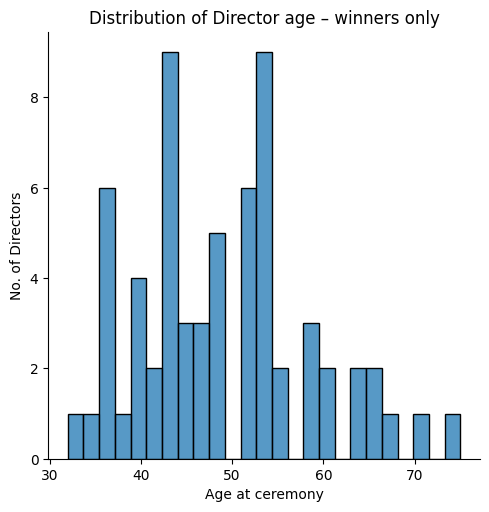

In [ ]:
# Age at ceremony - histogram
# winners only

plt.figure(figsize=(12,8), dpi = 300)

ax = sns.displot(x="Age_at_Ceremony", data=dir_winners_df, bins = 25)

ax.set(xlabel='Age at ceremony',
       ylabel='No. of Directors',
       title='Distribution of Director age – winners only')

plt.show()

In [ ]:
# much less normally distributed – could be an interesting contributing factor

/tmp/ipython-input-2791816017.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='Born in America?',


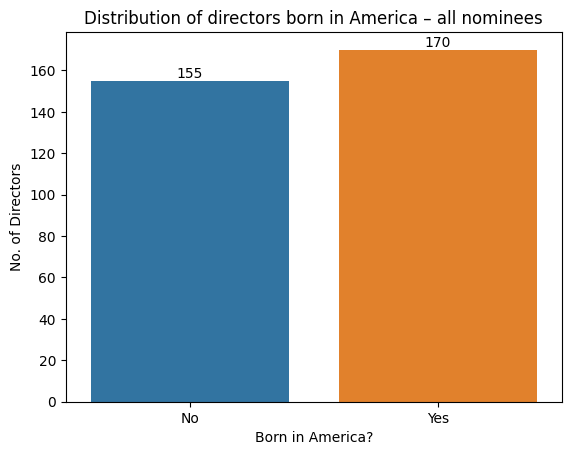

In [ ]:
# Born in America
# bar chart
# all nominees

#plt.figure(figsize=(8,6), dpi = 300)

ax = sns.countplot(x = 'Born_in_America',
                   data=dir_df,
                   hue='Born_in_America',
                   legend=False)

ax.set(xlabel='Born in America?',
       ylabel='No. of Directors',
       title='Distribution of directors born in America – all nominees',
       xticklabels=['No','Yes'])

for container in ax.containers:
    ax.bar_label(container)

plt.show()

/tmp/ipython-input-96791642.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='Born in America?',


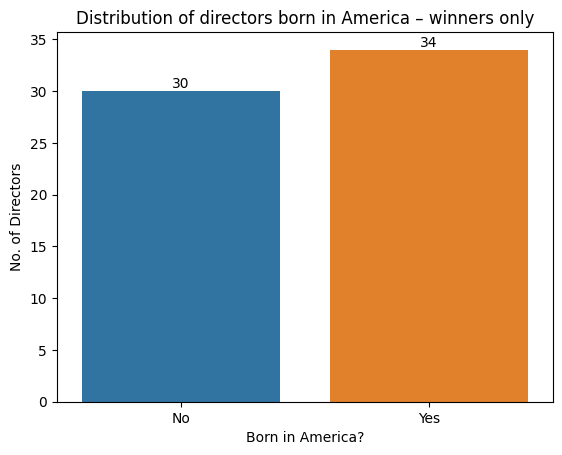

In [ ]:
# Born in America
# bar chart
# winners only

#plt.figure(figsize=(8,6), dpi = 300)

ax = sns.countplot(x = 'Born_in_America',
                   data=dir_winners_df,
                   hue='Born_in_America',
                   legend=False)

ax.set(xlabel='Born in America?',
       ylabel='No. of Directors',
       title='Distribution of directors born in America – winners only',
       xticklabels=['No','Yes'])

for container in ax.containers:
    ax.bar_label(container)

plt.show()

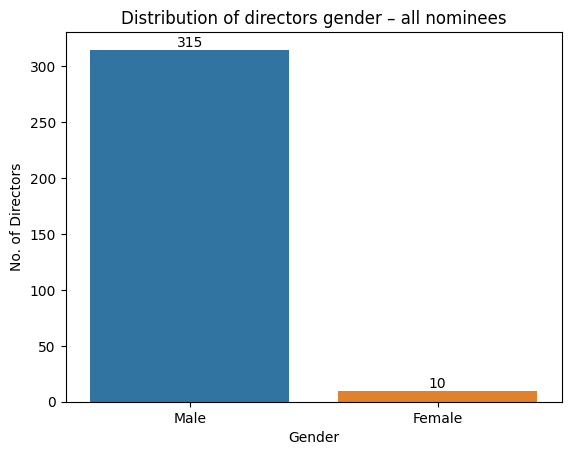

In [ ]:
# Gender
# bar chart
# all nominees

#plt.figure(figsize=(8,6), dpi = 300)

ax = sns.countplot(x = 'Gender',
                   data=dir_df,
                   hue='Gender',
                   legend=False)

ax.set(xlabel='Gender',
       ylabel='No. of Directors',
       title='Distribution of directors gender – all nominees')

for container in ax.containers:
    ax.bar_label(container)

plt.show()

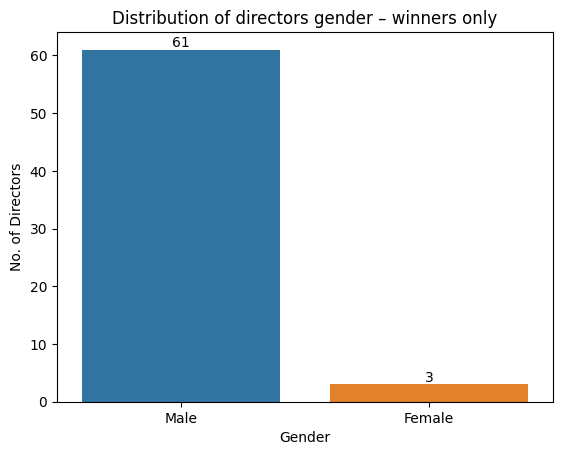

In [ ]:
# Gender
# bar chart
# winners only

#plt.figure(figsize=(8,6), dpi = 300)

ax = sns.countplot(x = 'Gender',
                   data=dir_winners_df,
                   hue='Gender',
                   legend=False)

ax.set(xlabel='Gender',
       ylabel='No. of Directors',
       title='Distribution of directors gender – winners only')

for container in ax.containers:
    ax.bar_label(container)

plt.show()

### NEW ACTING FEATURES

In [ ]:
# Wikidata scraper to find birth country, to create Born_in_America column (as with Director dataset)
# scraping in batches and with better rate limit handling
# Reference: Claude.ai

import requests
import time
import json
from urllib.parse import quote

class ActorCountryScraper:
    def __init__(self):
        self.base_url = "https://www.wikidata.org/w/api.php"
        self.sparql_url = "https://query.wikidata.org/sparql"

    def search_person(self, name):
        """Search for a person on Wikidata and return their entity ID"""
        try:
            # Try different name variations
            name_variations = [
                name,
                name.replace('ö', 'o').replace('ä', 'a').replace('ü', 'u'),  # Remove umlauts
                name.replace('é', 'e').replace('è', 'e').replace('á', 'a'),  # Remove accents
            ]

            for name_variant in name_variations:
                params = {
                    'action': 'wbsearchentities',
                    'search': name_variant,
                    'language': 'en',
                    'type': 'item',
                    'limit': 10,
                    'format': 'json'
                }

                response = requests.get(self.base_url, params=params, timeout=15)

                # Handle rate limiting with exponential backoff
                retry_count = 0
                while response.status_code == 429 and retry_count < 3:
                    wait_time = (2 ** retry_count) * 3  # 3, 6, 12 seconds
                    print(f"  Rate limited, waiting {wait_time} seconds... (attempt {retry_count + 1})")
                    time.sleep(wait_time)
                    retry_count += 1

                    response = requests.get(self.base_url, params=params, timeout=15)

                if response.status_code != 200:
                    continue

                data = response.json()

                # Look for any person in entertainment industry
                for item in data.get('search', []):
                    entity_id = item['id']
                    description = item.get('description', '').lower()

                    # Check if it's an actor or entertainment-related person
                    if any(keyword in description for keyword in ['actor', 'actress', 'film', 'movie', 'cinema', 'television', 'tv']):
                        return entity_id, item.get('description', '')

                    # Also check if they have actor occupation
                    if self.is_actor(entity_id):
                        return entity_id, item.get('description', '')

                # Small delay between name variations
                time.sleep(1)

            return None, None

        except requests.exceptions.RequestException as e:
            print(f"Request error searching for {name}: {e}")
            return None, None
        except Exception as e:
            print(f"Error searching for {name}: {e}")
            return None, None

    def is_actor(self, entity_id):
        """Check if the entity is an actor or related entertainment professional"""
        try:
            sparql_query = f"""
            SELECT ?item WHERE {{
              {{ wd:{entity_id} wdt:P106 wd:Q33999 . }}    # actor
              UNION
              {{ wd:{entity_id} wdt:P106 wd:Q10800557 . }} # film actor
              UNION
              {{ wd:{entity_id} wdt:P106 wd:Q10798782 . }} # television actor
              UNION
              {{ wd:{entity_id} wdt:P106 wd:Q2259451 . }}  # stage actor
            }}
            """

            headers = {'Accept': 'application/sparql-results+json'}
            response = requests.get(
                self.sparql_url,
                params={'query': sparql_query},
                headers=headers,
                timeout=10
            )

            if response.status_code == 200:
                data = response.json()
                return len(data['results']['bindings']) > 0

            return False

        except:
            return False

    def get_birth_country(self, entity_id):
        """Get birth country data"""
        if not entity_id:
            return None

        try:
            sparql_query = f"""
            SELECT ?countryLabel WHERE {{
              OPTIONAL {{
                wd:{entity_id} wdt:P19 ?birthPlace .     # place of birth
                ?birthPlace wdt:P17 ?country .           # country
              }}
              SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en" . }}
            }}
            LIMIT 1
            """

            headers = {'Accept': 'application/sparql-results+json'}
            response = requests.get(
                self.sparql_url,
                params={'query': sparql_query},
                headers=headers,
                timeout=15
            )

            # Handle rate limiting with exponential backoff
            retry_count = 0
            while response.status_code == 429 and retry_count < 3:
                wait_time = (2 ** retry_count) * 5  # 5, 10, 20 seconds
                print(f"    SPARQL rate limited, waiting {wait_time} seconds... (attempt {retry_count + 1})")
                time.sleep(wait_time)
                retry_count += 1

                response = requests.get(
                    self.sparql_url,
                    params={'query': sparql_query},
                    headers=headers,
                    timeout=15
                )

            if response.status_code == 200:
                data = response.json()
                results = data['results']['bindings']

                if results and len(results) > 0:
                    result = results[0]
                    if 'countryLabel' in result:
                        return result['countryLabel']['value']

            return None

        except requests.exceptions.RequestException as e:
            print(f"Request error getting data for {entity_id}: {e}")
            return None
        except Exception as e:
            print(f"Error getting data for {entity_id}: {e}")
            return None

    def is_american(self, country):
        """Determine if a country indicates American citizenship"""
        if not country:
            return None

        american_indicators = [
            'United States of America',
            'United States',
            'USA',
            'US'
        ]

        return country in american_indicators

    def process_actors(self, df, batch_size=50, resume_from=0):
        """Process all actors in the dataframe in batches with extended breaks"""
        unique_actors = df['Nominee'].unique()
        actor_data = {}

        print(f"Processing {len(unique_actors)} unique actors in batches of {batch_size}...")
        print(f"Starting from actor #{resume_from}")

        # Skip actors we've already processed if resuming
        actors_to_process = unique_actors[resume_from:]

        # Process in batches
        for batch_start in range(0, len(actors_to_process), batch_size):
            batch_end = min(batch_start + batch_size, len(actors_to_process))
            batch_actors = actors_to_process[batch_start:batch_end]

            actual_index = resume_from + batch_start
            print(f"\n=== BATCH {(actual_index // batch_size) + 1}: Processing actors {actual_index + 1}-{resume_from + batch_end} ===")

            for i, actor in enumerate(batch_actors):
                global_index = actual_index + i
                print(f"Progress: {global_index + 1}/{len(unique_actors)} ({(global_index + 1)/len(unique_actors)*100:.1f}%) - {actor}")

                # Search for actor with extended retry logic
                entity_id, description = self.search_person_with_backoff(actor)

                if entity_id:
                    # Get birth country data with extended retry logic
                    birth_country = self.get_birth_country_with_backoff(entity_id)
                    is_american = self.is_american(birth_country)

                    actor_data[actor] = {
                        'wikidata_id': entity_id,
                        'description': description,
                        'birth_country': birth_country,
                        'is_american': is_american
                    }

                    print(f"  → {birth_country}")
                else:
                    actor_data[actor] = {
                        'wikidata_id': None,
                        'description': None,
                        'birth_country': None,
                        'is_american': None
                    }
                    print(f"  → Not found")

                # Longer delays to be more respectful to the API
                time.sleep(4)

            # Extended break between batches (2 minutes)
            if batch_end < len(actors_to_process):
                print(f"\n🛑 Completed batch. Taking 2-minute break to respect rate limits...")
                time.sleep(120)

        return actor_data

    def search_person_with_backoff(self, name):
        """Search for a person with extended backoff for rate limits"""
        try:
            name_variations = [
                name,
                name.replace('ö', 'o').replace('ä', 'a').replace('ü', 'u'),
                name.replace('é', 'e').replace('è', 'e').replace('á', 'a'),
            ]

            for name_variant in name_variations:
                params = {
                    'action': 'wbsearchentities',
                    'search': name_variant,
                    'language': 'en',
                    'type': 'item',
                    'limit': 10,
                    'format': 'json'
                }

                response = requests.get(self.base_url, params=params, timeout=20)

                # Extended rate limiting with longer waits
                retry_count = 0
                while response.status_code == 429 and retry_count < 5:
                    wait_time = min((2 ** retry_count) * 10, 300)  # Max 5 minutes
                    print(f"    ⏳ Rate limited, waiting {wait_time} seconds... (attempt {retry_count + 1})")
                    time.sleep(wait_time)
                    retry_count += 1
                    response = requests.get(self.base_url, params=params, timeout=20)

                if response.status_code != 200:
                    continue

                data = response.json()

                for item in data.get('search', []):
                    entity_id = item['id']
                    description = item.get('description', '').lower()

                    if any(keyword in description for keyword in ['actor', 'actress', 'film', 'movie', 'cinema', 'television', 'tv']):
                        return entity_id, item.get('description', '')

                    if self.is_actor(entity_id):
                        return entity_id, item.get('description', '')

                time.sleep(2)  # Longer delay between name variations

            return None, None

        except Exception as e:
            print(f"    ❌ Error searching for {name}: {e}")
            return None, None

    def get_birth_country_with_backoff(self, entity_id):
        """Get birth country with extended backoff for rate limits"""
        if not entity_id:
            return None

        try:
            sparql_query = f"""
            SELECT ?countryLabel WHERE {{
              OPTIONAL {{
                wd:{entity_id} wdt:P19 ?birthPlace .
                ?birthPlace wdt:P17 ?country .
              }}
              SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en" . }}
            }}
            LIMIT 1
            """

            headers = {'Accept': 'application/sparql-results+json'}
            response = requests.get(
                self.sparql_url,
                params={'query': sparql_query},
                headers=headers,
                timeout=20
            )

            # Extended rate limiting with longer waits
            retry_count = 0
            while response.status_code == 429 and retry_count < 5:
                wait_time = min((2 ** retry_count) * 15, 300)  # Max 5 minutes
                print(f"    ⏳ SPARQL rate limited, waiting {wait_time} seconds... (attempt {retry_count + 1})")
                time.sleep(wait_time)
                retry_count += 1
                response = requests.get(
                    self.sparql_url,
                    params={'query': sparql_query},
                    headers=headers,
                    timeout=20
                )

            if response.status_code == 200:
                data = response.json()
                results = data['results']['bindings']

                if results and len(results) > 0:
                    result = results[0]
                    if 'countryLabel' in result:
                        return result['countryLabel']['value']

            return None

        except Exception as e:
            print(f"    ❌ Error getting country for {entity_id}: {e}")
            return None

    def create_output_dataframe(self, df, actor_data):
        """Create the output dataframe with birth country information"""
        result_df = df.copy()

        # Add new columns
        result_df['Wikidata_ID'] = None
        result_df['Wikidata_Description'] = None
        result_df['Birth_Country'] = None
        result_df['Is_American'] = None

        # Apply the data
        for idx, row in result_df.iterrows():
            actor = row['Nominee']
            if actor in actor_data:
                data = actor_data[actor]
                result_df.at[idx, 'Wikidata_ID'] = data['wikidata_id']
                result_df.at[idx, 'Wikidata_Description'] = data['description']
                result_df.at[idx, 'Birth_Country'] = data['birth_country']
                result_df.at[idx, 'Is_American'] = data['is_american']

        return result_df

    def print_country_summary(self, df):
        """Print summary statistics for birth countries"""
        total = len(df)
        found_data = df['Wikidata_ID'].notna().sum()

        print(f"\n=== BIRTH COUNTRY SUMMARY ===")
        print(f"Total nominations: {total}")
        print(f"Actors found in Wikidata: {found_data} ({found_data/total*100:.1f}%)")

        # Country summary
        found_countries = df['Birth_Country'].notna().sum()
        if found_countries > 0:
            american_count = df['Is_American'].sum() if df['Is_American'].notna().any() else 0
            print(f"\nCOUNTRY DATA:")
            print(f"Birth countries found: {found_countries} ({found_countries/total*100:.1f}%)")
            print(f"American actors: {american_count}")
            print(f"Non-American actors: {found_countries - american_count}")

            country_counts = df['Birth_Country'].value_counts().head(10)
            print(f"\nTop countries:")
            for country, count in country_counts.items():
                print(f"  {country}: {count}")

        # Show unmatched actors
        unmatched = df[df['Wikidata_ID'].isna()]['Nominee'].unique()
        if len(unmatched) > 0:
            print(f"\n=== UNMATCHED ACTORS ({len(unmatched)} total) ===")
            for actor in unmatched[:20]:  # Show first 20
                print(f"- {actor}")
            if len(unmatched) > 20:
                print(f"... and {len(unmatched) - 20} more")

# Main function with batch processing and resume capability
def get_actor_countries(df, batch_size=50, resume_from=0):
    """Get birth country data for actors with batch processing"""
    scraper = ActorCountryScraper()

    print(f"🚀 Starting actor country scraping...")
    print(f"📊 Total unique actors to process: {len(df['Nominee'].unique())}")
    print(f"📦 Batch size: {batch_size}")
    print(f"▶️ Resume from actor #{resume_from + 1}")

    # Process actors in batches
    actor_data = scraper.process_actors(df, batch_size=batch_size, resume_from=resume_from)

    # Create output dataframe
    result_df = scraper.create_output_dataframe(df, actor_data)

    # Print summary
    scraper.print_country_summary(result_df)

    return result_df


In [ ]:
# calling scraper function

act_countries = get_actor_countries(act_df, batch_size=50, resume_from=0)

🚀 Starting actor country scraping...
📊 Total unique actors to process: 723
📦 Batch size: 50
▶️ Resume from actor #1
Processing 723 unique actors in batches of 50...
Starting from actor #0

=== BATCH 1: Processing actors 1-50 ===
Progress: 1/723 (0.1%) - Burt Lancaster
  → United States
Progress: 2/723 (0.3%) - Trevor Howard
  → United Kingdom
Progress: 3/723 (0.4%) - Jack Lemmon
  → United States
Progress: 4/723 (0.6%) - Laurence Olivier
  → United Kingdom
Progress: 5/723 (0.7%) - Spencer Tracy
  → United States
Progress: 6/723 (0.8%) - Shirley MacLaine
  → United States
Progress: 7/723 (1.0%) - Elizabeth Taylor
  → United Kingdom
Progress: 8/723 (1.1%) - Greer Garson
  → United Kingdom
Progress: 9/723 (1.2%) - Deborah Kerr
  → United Kingdom
Progress: 10/723 (1.4%) - Melina Mercouri
  → Greece
Progress: 11/723 (1.5%) - Jack Kruschen
  → Canada
Progress: 12/723 (1.7%) - Peter Ustinov
  → United Kingdom
Progress: 13/723 (1.8%) - Sal Mineo
  → United States
Progress: 14/723 (1.9%) - Chil

In [ ]:
act_countries

,Category,Film,Oscar_Year,Nominee,Winner,Prev_Oscar_act_noms_count,Prev_Oscar_act_wins_count,Prev_Oscar_act_nom_binary,Prev_Oscar_act_win_binary,Oscar_nom_picture,...,MPAA_PG-13,MPAA_R,MPAA_NC-17,Runtime,Produced_America,English_spoken,Wikidata_ID,Wikidata_Description,Birth_Country,Is_American
0,Actor,Elmer Gantry,1961,Burt Lancaster,1,0,0,0,0,1,...,0,0,0,146,1,1,Q160528,American actor (1913–1994),United States,True
1,Actor,Sons and Lovers,1961,Trevor Howard,0,0,0,0,0,1,...,0,0,0,103,0,1,Q343037,"English film, stage and television actor (1913...",United Kingdom,False
2,Actor,The Apartment,1961,Jack Lemmon,0,0,0,0,0,1,...,0,0,0,125,1,1,Q94123,American actor (1925–2001),United States,True
3,Actor,The Entertainer,1961,Laurence Olivier,0,0,0,0,0,0,...,0,0,0,104,0,1,Q55245,English actor and director (1907–1989),United Kingdom,False
4,Actor,Inherit the Wind,1961,Spencer Tracy,0,0,0,0,0,0,...,0,0,0,128,1,1,Q71275,American actor (1900–1967),United States,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,Supporting Actress,The Brutalist,2025,Felicity Jones,0,1,0,1,0,1,...,0,1,0,215,1,1,Q234447,English actress,United Kingdom,False
1299,Supporting Actress,A Complete Unknown,2025,Monica Barbaro,0,0,0,0,0,1,...,0,1,0,140,1,1,Q26703036,American actress,United States,True
1300,Supporting Actress,Conclave,2025,Isabella Rossellini,0,0,0,0,0,1,...,0,0,0,120,1,1,Q203840,Italian-American actress (born 1952),Italy,False
1301,Supporting Actress,Emilia Perez,2025,Zoe Saldana,1,0,0,0,0,1,...,0,1,0,132,1,1,Q190162,American actress,United States,True


In [ ]:
# renaming Is_American column to Born_in_America for clarity
act_countries.rename(columns={'Is_American': 'Born_in_America'}, inplace=True)

In [ ]:
# checking missing values

act_countries['Born_in_America'].isna().sum()

np.int64(2)

In [ ]:
# seeing which unique directors have missing Born_in_America

act_countries[act_countries['Born_in_America'].isna()]['Nominee'].unique()

array(['Dexter Gordon', 'Andra Day'], dtype=object)

In [ ]:
# filling in missing Born_in_America for above list of unmatched actors according to Nominee name
# filling with boolean values to match Wikidata scraper input

missing_actors_born_america = {
    'Dexter Gordon': True,
    'Andra Day': True
}

act_countries['Born_in_America'] = act_countries['Born_in_America'].fillna(act_countries['Nominee'].map(missing_actors_born_america))

/tmp/ipython-input-2315903416.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  act_countries['Born_in_America'] = act_countries['Born_in_America'].fillna(act_countries['Nominee'].map(missing_actors_born_america))


In [ ]:
# checking missing values - should be 0

act_countries['Born_in_America'].isna().sum()

np.int64(0)

In [ ]:
# converting the column to binary 1s and 0s

act_countries['Born_in_America'] = act_countries['Born_in_America'].astype(int)

In [ ]:
# dropping columns not needed and renaming back to act_df
act_df = act_countries.drop(['Wikidata_ID', 'Wikidata_Description', 'Birth_Country'], axis=1)

In [ ]:
act_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1300 entries, 0 to 1302
Data columns (total 53 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Category                   1300 non-null   object 
 1   Film                       1300 non-null   object 
 2   Oscar_Year                 1300 non-null   int64  
 3   Nominee                    1300 non-null   object 
 4   Winner                     1300 non-null   int64  
 5   Prev_Oscar_act_noms_count  1300 non-null   int64  
 6   Prev_Oscar_act_wins_count  1300 non-null   int64  
 7   Prev_Oscar_act_nom_binary  1300 non-null   int64  
 8   Prev_Oscar_act_win_binary  1300 non-null   int64  
 9   Oscar_nom_picture          1300 non-null   int64  
 10  Total_Oscar_noms           1300 non-null   int64  
 11  Rating_IMDB                1300 non-null   float64
 12  Rating_rtaudience          1300 non-null   int64  
 13  Rating_rtcritic            1300 non-null   int64  
 1

In [ ]:
# writing actor dataset at this point to csv, to manually fill row with missing values, and add Real_person feature

act_df_existing_path = '/content/drive/My Drive/MY STUFF/MSC/DISSERTATION/SHARED FOR NOTEBOOK/acting_with_birth_country-2.csv'

act_df.to_csv(act_df_existing_path, index=False, header=True, sep=',', encoding='utf-8')

### NEW ACTING FEATURE VISUALISATIONS

In [3]:
# Importing complete actor dataset, with Real_person feature added

act_data = '18V8j_QbeESK-afrY0hoFX6yzZgDeE4y9'
act_url = f'https://drive.google.com/uc?id={act_data}'

act_df = pd.read_csv(act_url)
act_df

,Category,Film,Oscar_Year,Nominee,Winner,Prev_Oscar_act_noms_count,Prev_Oscar_act_wins_count,Prev_Oscar_act_nom_binary,Prev_Oscar_act_win_binary,Oscar_nom_picture,...,Genre_family,Genre_sport,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Born_in_America,Real_person
0,Actor,Elmer Gantry,1961,Burt Lancaster,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
1,Actor,Sons and Lovers,1961,Trevor Howard,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,Actor,The Apartment,1961,Jack Lemmon,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
3,Actor,The Entertainer,1961,Laurence Olivier,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,Actor,Inherit the Wind,1961,Spencer Tracy,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1295,Supporting Actress,The Brutalist,2025,Felicity Jones,0,1,0,1,0,1,...,0,0,0,0,0,0,1,0,0,0
1296,Supporting Actress,A Complete Unknown,2025,Monica Barbaro,0,0,0,0,0,1,...,0,0,0,0,0,0,1,0,1,1
1297,Supporting Actress,Conclave,2025,Isabella Rossellini,0,0,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
1298,Supporting Actress,Emilia Perez,2025,Zoe Saldana,1,0,0,0,0,1,...,0,0,0,0,0,0,1,0,1,0


In [4]:
# create df of Best Acting winners, for visualisations

act_winners_df = act_df[act_df['Winner'] == 1]

act_winners_df

,Category,Film,Oscar_Year,Nominee,Winner,Prev_Oscar_act_noms_count,Prev_Oscar_act_wins_count,Prev_Oscar_act_nom_binary,Prev_Oscar_act_win_binary,Oscar_nom_picture,...,Genre_family,Genre_sport,Genre_western,MPAA_G,MPAA_PG,MPAA_PG-13,MPAA_R,MPAA_NC-17,Born_in_America,Real_person
0,Actor,Elmer Gantry,1961,Burt Lancaster,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
6,Actress,BUtterfield 8,1961,Elizabeth Taylor,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
11,Supporting Actor,Spartacus,1961,Peter Ustinov,1,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,1
15,Supporting Actress,Elmer Gantry,1961,Shirley Jones,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
20,Actor,Judgment at Nuremberg,1962,Maximilian Schell,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1276,Supporting Actress,The Holdovers,2024,Da'Vine Joy Randolph,1,0,0,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1280,Actor,The Brutalist,2025,Adrien Brody,1,1,1,1,1,1,...,0,0,0,0,0,0,1,0,1,0
1285,Actress,Anora,2025,Mikey Madison,1,0,0,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1294,Supporting Actor,A Real Pain,2025,Kieran Culkin,1,0,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0


/tmp/ipython-input-57521913.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='Born in America?',


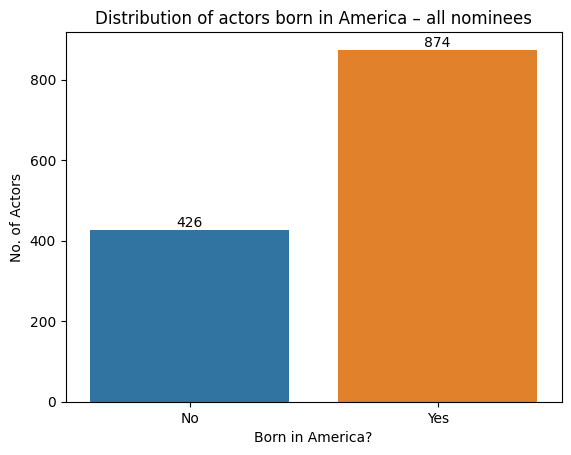

In [5]:
# Born_in_America (binary)
# bar chart
# all nominees

#plt.figure(figsize=(8,6), dpi = 300)

ax = sns.countplot(x = 'Born_in_America',
                   data=act_df,
                   hue='Born_in_America',
                   legend=False)

ax.set(xlabel='Born in America?',
       ylabel='No. of Actors',
       title='Distribution of actors born in America – all nominees',
       xticklabels=['No','Yes'])

for container in ax.containers:
    ax.bar_label(container)

plt.show()

/tmp/ipython-input-770206645.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='Born in America?',


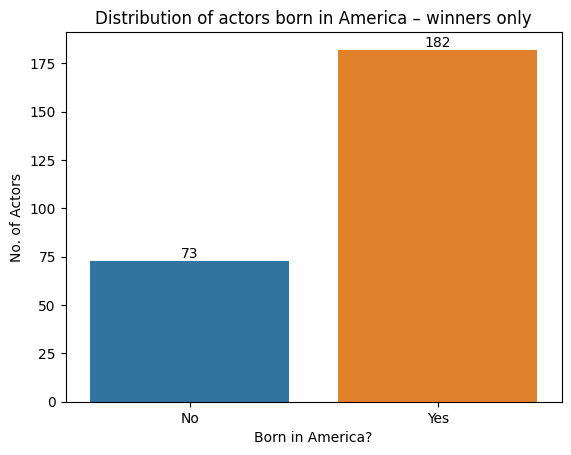

In [6]:
# Born_in_America (binary)
# bar chart
# winners only

#plt.figure(figsize=(8,6), dpi = 300)

ax = sns.countplot(x = 'Born_in_America',
                   data=act_winners_df,
                   hue='Born_in_America',
                   legend=False)

ax.set(xlabel='Born in America?',
       ylabel='No. of Actors',
       title='Distribution of actors born in America – winners only',
       xticklabels=['No','Yes'])

for container in ax.containers:
    ax.bar_label(container)

plt.show()

/tmp/ipython-input-1858583707.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='Playing a real person?',


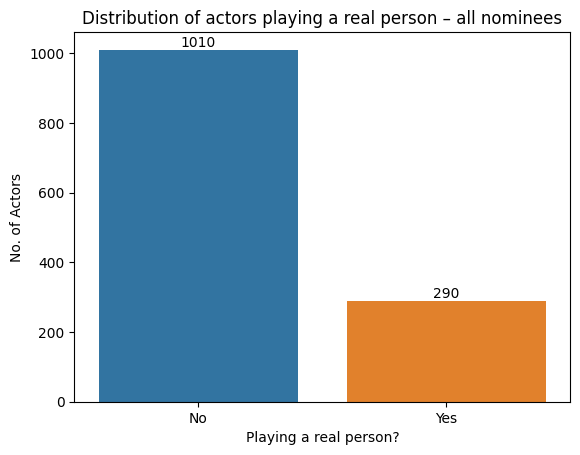

In [7]:
# Real_person (binary)
# bar chart
# all nominees

#plt.figure(figsize=(8,6), dpi = 300)

ax = sns.countplot(x = 'Real_person',
                   data=act_df,
                   hue='Real_person',
                   legend=False)

ax.set(xlabel='Playing a real person?',
       ylabel='No. of Actors',
       title='Distribution of actors playing a real person – all nominees',
       xticklabels=['No','Yes'])

for container in ax.containers:
    ax.bar_label(container)

plt.show()

/tmp/ipython-input-2092826043.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(xlabel='Playing a real person?',


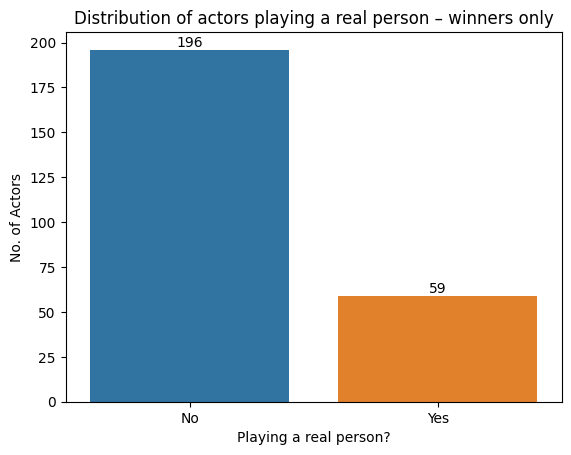

In [8]:
# Real_person (binary)
# bar chart
# winners only

#plt.figure(figsize=(8,6), dpi = 300)

ax = sns.countplot(x = 'Real_person',
                   data=act_winners_df,
                   hue='Real_person',
                   legend=False)

ax.set(xlabel='Playing a real person?',
       ylabel='No. of Actors',
       title='Distribution of actors playing a real person – winners only',
       xticklabels=['No','Yes'])

for container in ax.containers:
    ax.bar_label(container)

plt.show()

# **References**

Anthropic. (n.d.) *Claude.ai*. [Online] Available at: https://claude.ai/ (Accessed: 18 September 2025).

IMDb. *IMDb Data Files Available for Download*. Available at: https://datasets.imdbws.com/ (Accessed: 18 September 2025).

Saturn Cloud. (2022) *How to reorder columns in Pandas*. [Blog] Saturn Cloud. Available at: https://saturncloud.io/blog/pandas-tips-reorder-columns/ (Accessed: 18 September 2025).

The Academy of Motion Picture Arts and Sciences. *Oscars Ceremonies*. Available at: https://www.oscars.org/oscars/ceremonies/ (Accessed: 18 September 2025).